# SigerIQ: Arsitektur Hybrid Ordinal-Ensemble Berbasis Model-Based Imputation, Cumulative Probit/Logit, Regularized GBDT, dan Strict Nested-CV Threshold Optimization untuk Prediksi Pertumbuhan UMKM Digital Provinsi Lampung

---

### Informasi Resmi Tim dan Kompetisi

| Parameter | Keterangan |
| :--- | :--- |
| **Nama Solusi (Brand)** | **SigerIQ** (*Petakan Jejak Digitalnya, Akselerasi Tumbuh UMKM-nya*) |
| **Nama Kompetisi** | **Kompetisi Nasional GEMATIK VI 2026 — Babak Final Cabang Data Science** |
| **Penyelenggara** | Fakultas Teknik dan Ilmu Komputer, **Universitas Teknokrat Indonesia** |
| **Tema Lomba** | *"Empowering Global Innovators for an Intelligent Future"* |
| **Nama Tim** | **ditantang habib** |
| **Ketua Tim / Peneliti 1** | **Rizki Piji Fathoni** (NIM: 24031554029) |
| **Anggota Tim / Peneliti 2** | **Rahmawati Dian Pratiwi** (NIM: 24031554183) |
| **Afiliasi Akademik** | **Program Studi S1 Sains Data**, FMIPA, **Universitas Negeri Surabaya (UNESA)** |
| **Metrik Evaluasi Resmi** | **Macro F1-Score** (3 Kelas: `Menurun`, `Stabil`, `Tumbuh`) pada 1.400 baris Holdout |
| **Protokol Validasi** | Mandatory Split (`test_size=0.2, stratify, random_state=42`) + 10-Fold Strict Nested Stratified CV |

---

### Ringkasan Eksekutif Pencapaian Empiris (Hasil Eksekusi Aktual)

| Milestone Evaluasi | Metrik Aktual | Makna Strategis |
| :--- | :--- | :--- |
| **Baseline Mentah (Default HistGBDT)** | Macro F1: **0.64742** \| LogLoss: 0.79175 | Titik jangkar awal sebelum pembersihan data korup dan rekayasa fitur ordinal. |
| **Single Model Terbaik (10-Fold CV)** | Multiclass CatBoost (Reg): **0.67563** \| Ordinal Probit LogLoss: **0.70082** | Membuktikan struktur skor laten ordinal Gaussian pada data sintetis UMKM Lampung. |
| **Hybrid Ensemble (10-Fold Nested-CV)** | Macro F1: **0.67562** \| LogLoss: **0.70029** | Kombinasi Ordinal Probit + Ordinal Binary LightGBM + CatBoost + XGBoost + LogReg dengan optimasi 2-Threshold Ordinal (`c0=0.6038, c1=1.4005`). |
| **Evaluasi Akhir Holdout (Unseen 1.400)** | Macro F1: **0.66194** \| Accuracy: **0.65571** \| QWK: **0.66727** | Generalisasi kokoh (`gap = -0.01368`), dengan **97,72%** kesalahan hanya terjadi pada kelas bertetangga dan hanya **0,79%** kesalahan ekstrem (`Menurun <-> Tumbuh`). |

---

### Penyelarasan Sustainable Development Goals (SDGs)

1. **SDG 8 (Pekerjaan Layak dan Pertumbuhan Ekonomi):** Pemetaan risiko penurunan omzet UMKM digital Lampung untuk intervensi pendampingan tepat sasaran.
2. **SDG 9 (Industri, Inovasi, dan Infrastruktur):** Mengkuantifikasi dampak langsung kualitas internet, adopsi pembayaran QRIS/Multi-kanal, dan literasi digital terhadap daya saing usaha.
3. **SDG 10 (Berkurangnya Kesenjangan):** Menjembatani disparitas pertumbuhan UMKM antara pusat urban (Bandar Lampung, Metro, Pringsewu) dan kabupaten periferal.
4. **SDG 17 (Kemitraan untuk Mencapai Tujuan):** Menyediakan sistem intelijen berbasis bukti bagi Pemerintah Provinsi Lampung, dinas koperasi/UMKM, dan ekosistem pelatihan digital.

## 0. Konfigurasi Lingkungan & Instalasi Otomatis (Cloud-Ready)
Sel ini memastikan seluruh pustaka pendukung (`lightgbm`, `xgboost`, `catboost`, `shap`) tersedia di lingkungan cloud eksternal (Google Colab / Kaggle) serta mengatur parameter global dan penyimpanan aset grafik 300-DPI untuk PPT.

In [1]:
import importlib, subprocess, sys

REQUIRED_PKGS = {
    "lightgbm": "lightgbm",
    "xgboost": "xgboost",
    "catboost": "catboost",
    "shap": "shap",
}

for mod_name, pip_name in REQUIRED_PKGS.items():
    if importlib.util.find_spec(mod_name) is None:
        print(f"Menginstal {pip_name} ...")
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
            print(f"  ✓ {pip_name} berhasil diinstal.")
        except Exception as e:
            print(f"  ⚠ Gagal menginstal {pip_name} (akan dilewati secara aman): {e}")
    else:
        print(f"  ✓ {pip_name} sudah tersedia.")

  ✓ lightgbm sudah tersedia.
  ✓ xgboost sudah tersedia.
Menginstal catboost ...
  ✓ catboost berhasil diinstal.
  ✓ shap sudah tersedia.


In [2]:
import os
import gc
import time
import json
import zipfile
import warnings
import importlib
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from scipy.special import expit, ndtr
from scipy.stats import norm

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    f1_score, log_loss, accuracy_score, classification_report,
    confusion_matrix, cohen_kappa_score, r2_score
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge, BayesianRidge
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeRegressor, export_text

HAS_LGBM = importlib.util.find_spec("lightgbm") is not None
HAS_XGB  = importlib.util.find_spec("xgboost") is not None
HAS_CAT  = importlib.util.find_spec("catboost") is not None
HAS_SHAP = importlib.util.find_spec("shap") is not None

if HAS_LGBM:
    import lightgbm as lgb
if HAS_XGB:
    import xgboost as xgb
if HAS_CAT:
    from catboost import CatBoostClassifier
if HAS_SHAP:
    import shap

NAMA_TIM = "NamaTim"
SEED = 42
N_SPLITS_MAIN = 10
N_SPLITS_ABLATION = 5

np.random.seed(SEED)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.08)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#CCCCCC",
    "grid.alpha": 0.35,
    "legend.frameon": True,
    "legend.facecolor": "white",
    "legend.edgecolor": "#E0E0E0",
})

CLASS_NAMES = ["Menurun", "Stabil", "Tumbuh"]
CLASS_TO_INT = {"Menurun": 0, "Stabil": 1, "Tumbuh": 2}
INT_TO_CLASS = {0: "Menurun", 1: "Stabil", 2: "Tumbuh"}
PALETTE_TARGET = {"Menurun": "#D94F4F", "Stabil": "#3B82F6", "Tumbuh": "#10B981"}

print(f"Environment siap | LGBM={HAS_LGBM}, XGB={HAS_XGB}, CAT={HAS_CAT}, SHAP={HAS_SHAP}")

Environment siap | LGBM=True, XGB=True, CAT=True, SHAP=True


## 1. Pemahaman Masalah & Protokol Pembagian Data (Wajib — Section 3a)

Sesuai ketentuan Babak Final GEMATIK VI:
- Dataset `data_mentah.csv` berisi **7.000 baris** UMKM sintetis Provinsi Lampung (21 kolom).
- Pembagian **WAJIB** dilakukan sebelum manipulasi/pengurutan apa pun dengan `test_size=0.2`, `stratify=df["Status_Pertumbuhan"]`, `random_state=42`.
- **`train` (5.600 baris):** Digunakan untuk seluruh EDA, *feature engineering*, *preprocessing fitting*, pelatihan, validasi silang (CV), *ensembling*, dan *threshold optimization*.
- **`holdout` (1.400 baris):** **DIKUNCI** dan hanya dibuka SATU KALI pada bagian evaluasi akhir & pembuatan berkas submission `<NamaTim>.csv`.

In [3]:
def find_file(filename):
    candidates = [
        Path(filename),
        Path("FINAL") / filename,
        Path("/content") / filename,
        Path("/content/drive/MyDrive") / filename,
    ]
    for p in candidates:
        if p.exists():
            return p
    for root in [Path("/kaggle/input"), Path(".")]:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    return None

DATA_PATH = find_file("data_mentah.csv")
SAMPLE_SUB_PATH = find_file("sample_submission.csv")

if DATA_PATH is None:
    try:
        from google.colab import files
        print("File 'data_mentah.csv' tidak ditemukan. Silakan unggah data_mentah.csv (dan sample_submission.csv):")
        uploaded = files.upload()
        DATA_PATH = find_file("data_mentah.csv")
        SAMPLE_SUB_PATH = find_file("sample_submission.csv")
    except Exception:
        raise FileNotFoundError(
            "File 'data_mentah.csv' tidak ditemukan! Pastikan file berada di direktori kerja notebook."
        )

print(f"Dataset ditemukan          : {DATA_PATH}")
print(f"Sample submission ditemukan: {SAMPLE_SUB_PATH}")

df = pd.read_csv(DATA_PATH)
train, holdout = train_test_split(
    df,
    test_size=0.2,
    stratify=df["Status_Pertumbuhan"],
    random_state=42,
)

train_df = train.copy().reset_index(drop=True)
holdout_ids = holdout["ID"].values.copy()
y_train = train_df["Status_Pertumbuhan"].map(CLASS_TO_INT).values

print(f"\nDimensi total   : {df.shape}")
print(f"Dimensi train   : {train_df.shape} (80%)")
print(f"Dimensi holdout : {holdout.shape} (20% — TERKUNCI)")

if SAMPLE_SUB_PATH is not None:
    sample_sub = pd.read_csv(SAMPLE_SUB_PATH)
    exact_order_match = (holdout["ID"].values == sample_sub["ID"].values).all()
    exact_set_match   = (set(holdout["ID"].values) == set(sample_sub["ID"].values))
    print(f"Verifikasi ID holdout vs sample_submission (urutan persis): {exact_order_match}")
    print(f"Verifikasi ID holdout vs sample_submission (himpunan sama): {exact_set_match}")
    assert exact_set_match, "PERINGATAN: ID holdout tidak cocok dengan sample_submission.csv!"

X_holdout_raw = holdout.drop(columns=["Status_Pertumbuhan"]).copy().reset_index(drop=True)
y_holdout_true = holdout["Status_Pertumbuhan"].map(CLASS_TO_INT).values

Dataset ditemukan          : data_mentah.csv
Sample submission ditemukan: sample_submission.csv

Dimensi total   : (7000, 21)
Dimensi train   : (5600, 21) (80%)
Dimensi holdout : (1400, 21) (20% — TERKUNCI)
Verifikasi ID holdout vs sample_submission (urutan persis): True
Verifikasi ID holdout vs sample_submission (himpunan sama): True


#### Interpretasi Verifikasi Split dan Tabel Keputusan Tahap Akuisisi

Pembagian data menghasilkan tepat **5.600 baris `train` (80%)** dan **1.400 baris `holdout` (20%)** tanpa duplikasi ID, dengan urutan seluruh 1.400 ID pada `holdout` terverifikasi **100% identik** terhadap `sample_submission.csv`.

| Temuan | Dampak Pemodelan | Tindakan Konkret |
| :--- | :--- | :--- |
| Partisi wajib `test_size=0.2, stratify, random_state=42` menghasilkan urutan ID `holdout` identik dengan `sample_submission.csv`. | Menjamin evaluasi akhir sepenuhnya adil dan dapat direproduksi oleh Dewan Juri. | Mengunci partisi `holdout` secara ketat hingga Bagian 5 dan Bagian 8; seluruh audit, imputasi, *feature engineering*, dan *tuning* dijalankan murni pada `train`. |

## 2. Eksplorasi Data (EDA) & Audit Kualitas Data *(Khusus pada Data Latih)*

Seluruh pemeriksaan distribusi, korelasi, anomali, dan hubungan fitur-target dilakukan **hanya pada `train_df` (5.600 baris)** guna menjaga integritas validasi.

### 2.1 Audit Kualitas Data Komprehensif
Kita memeriksa secara sistematis:
1. Duplikasi baris & duplikasi `ID`
2. Inkonsistensi penulisan/kapitalisasi pada variabel kategorikal
3. *Missing values* dan pengujian mekanisme *missingness* (**Uji Chi-Square MCAR** + **Uji Prediktabilitas $R^2$ / Akurasi** untuk memilih strategi imputasi terbaik)
4. *Outliers* ekstrem, *skewness*, dan **anomali presisi desimal** (*corrupted synthetic noise*)
5. Anomali konsistensi logika domain bisnis UMKM

In [4]:
num_cols_raw = train_df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols_raw = [c for c in train_df.select_dtypes(exclude=[np.number]).columns if c not in ["ID", "Status_Pertumbuhan"]]

print("=== 1. DUPLIKASI ===")
print(f"Duplikat baris persis : {train_df.duplicated().sum()}")
print(f"Duplikat ID           : {train_df['ID'].duplicated().sum()}")

print("\n=== 2. DISTRIBUSI TARGET (TRAIN) ===")
tgt_vc = train_df["Status_Pertumbuhan"].value_counts().reindex(CLASS_NAMES)
tgt_pct = (train_df["Status_Pertumbuhan"].value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2)
display(pd.DataFrame({"Jumlah": tgt_vc, "Proporsi (%)": tgt_pct}))

print("\n=== 3. AUDIT INKONSISTENSI TEKS KATEGORIKAL ===")
for c in cat_cols_raw:
    raw_u = train_df[c].dropna().unique()
    norm_u = set(v.strip().lower() for v in raw_u)
    if len(raw_u) != len(norm_u):
        n_upper = train_df[c].dropna().str.isupper().sum()
        print(f"  ⚠ {c}: {len(raw_u)} nilai unik mentah -> seharusnya {len(norm_u)} nilai unik! ({n_upper} baris ALL-CAPS)")
    else:
        print(f"  ✓ {c}: {len(raw_u)} nilai unik konsisten.")

print("\n=== 4. AUDIT MISSING VALUES & UJI CHI-SQUARE MCAR TERHADAP TARGET ===")
miss_rows = []
for c in train_df.columns:
    n_m = train_df[c].isnull().sum()
    if n_m > 0:
        ct = pd.crosstab(train_df[c].isnull(), train_df["Status_Pertumbuhan"])
        _, p_val, _, _ = stats.chi2_contingency(ct)
        miss_rows.append({
            "Kolom": c,
            "Tipe": str(train_df[c].dtype),
            "Jumlah_Missing": n_m,
            "Persen_Missing (%)": round(n_m / len(train_df) * 100, 2),
            "Chi2_p_value_vs_Target": round(p_val, 4),
            "Mekanisme_vs_Target": "MCAR (Independen)" if p_val > 0.05 else "Berhubungan"
        })
miss_df = pd.DataFrame(miss_rows).sort_values("Persen_Missing (%)", ascending=False)
display(miss_df)

print("\n=== 5. RINGKASAN STATISTIK NUMERIK, SKEWNESS & ANOMALI PRESISI DESIMAL ===")
num_summary = train_df[num_cols_raw].describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T[["count", "min", "50%", "95%", "99%", "max"]]
num_summary["Skewness"] = train_df[num_cols_raw].skew().round(2)
num_summary["Negatif"] = (train_df[num_cols_raw] < 0).sum()
num_summary["Nol"] = (train_df[num_cols_raw] == 0).sum()
num_summary["Dec_gt_2"] = [
    train_df[c].dropna().astype(str).apply(lambda s: len(s.split(".")[1]) if "." in s else 0).gt(2).sum()
    for c in num_cols_raw
]
display(num_summary.round(2))

bad_omz_mask = train_df["Omzet_Bulanan_Juta"].notnull() & (
    train_df["Omzet_Bulanan_Juta"].astype(str).apply(lambda s: len(s.split(".")[1]) if "." in s else 0) > 2
)
print(f"\n=== 6. TEMUAN KRITIS: CORRUPTED OUTLIERS PADA Omzet_Bulanan_Juta ===")
print(f"Jumlah baris dengan >2 desimal (train) : {bad_omz_mask.sum()} ({bad_omz_mask.mean()*100:.2f}%)")
print(f"Statistik Omzet korup (>2 desimal)     : min={train_df.loc[bad_omz_mask, 'Omzet_Bulanan_Juta'].min():.2f}, "
      f"median={train_df.loc[bad_omz_mask, 'Omzet_Bulanan_Juta'].median():.2f}, "
      f"max={train_df.loc[bad_omz_mask, 'Omzet_Bulanan_Juta'].max():.2f}")
print(f"Statistik Omzet normal (<=2 desimal)   : min={train_df.loc[~bad_omz_mask, 'Omzet_Bulanan_Juta'].min():.2f}, "
      f"median={train_df.loc[~bad_omz_mask, 'Omzet_Bulanan_Juta'].median():.2f}, "
      f"max={train_df.loc[~bad_omz_mask, 'Omzet_Bulanan_Juta'].max():.2f}")
print("Proporsi target pada Omzet korup       :",
      train_df.loc[bad_omz_mask, "Status_Pertumbuhan"].value_counts(normalize=True).reindex(CLASS_NAMES).round(3).to_dict())
print("Proporsi target keseluruhan (populasi) :",
      train_df["Status_Pertumbuhan"].value_counts(normalize=True).reindex(CLASS_NAMES).round(3).to_dict())
print("-> KESIMPULAN: Omzet korup memiliki distribusi target menyerupai populasi (bukan didominasi 'Tumbuh')!")
print("   Artinya nilai ekstrem tersebut adalah NOISE pengukuran, sehingga HARUS dijadikan NaN & diimputasi (bukan di-cap di nilai tinggi!).")

print("\n=== 7. ANOMALI KONSISTENSI DOMAIN ===")
print(f"  - Jumlah_Ulasan == 0 tetapi Rating_Rata_Rata terisi     : {((train_df['Jumlah_Ulasan'] == 0) & train_df['Rating_Rata_Rata'].notnull()).sum()} baris")
print(f"  - Platform_Digital_Aktif == 0 tetapi Posting > 0        : {((train_df['Platform_Digital_Aktif'] == 0) & (train_df['Frekuensi_Posting_Per_Minggu'] > 0)).sum()} baris")
print(f"  - Platform_Digital_Aktif == 0 tetapi Followers > 0      : {((train_df['Platform_Digital_Aktif'] == 0) & (train_df['Followers_Media_Sosial'] > 0)).sum()} baris")
print(f"  - Usia_Pemilik - (Lama_Usaha_Bulan/12) < 10 tahun       : {((train_df['Usia_Pemilik'] - train_df['Lama_Usaha_Bulan']/12) < 10).sum()} baris")

=== 1. DUPLIKASI ===
Duplikat baris persis : 0
Duplikat ID           : 0

=== 2. DISTRIBUSI TARGET (TRAIN) ===


,Jumlah,Proporsi (%)
Status_Pertumbuhan,,
Menurun,1512,27.0
Stabil,2408,43.0
Tumbuh,1680,30.0



=== 3. AUDIT INKONSISTENSI TEKS KATEGORIKAL ===
  ⚠ Kabupaten_Kota: 30 nilai unik mentah -> seharusnya 15 nilai unik! (50 baris ALL-CAPS)
  ✓ Sektor_Usaha: 6 nilai unik konsisten.
  ✓ Pendidikan_Pemilik: 4 nilai unik konsisten.
  ✓ Pernah_Pelatihan: 2 nilai unik konsisten.
  ✓ Kualitas_Internet: 3 nilai unik konsisten.
  ✓ Metode_Pembayaran_Digital: 3 nilai unik konsisten.
  ✓ Akses_Kredit: 2 nilai unik konsisten.

=== 4. AUDIT MISSING VALUES & UJI CHI-SQUARE MCAR TERHADAP TARGET ===


,Kolom,Tipe,Jumlah_Missing,Persen_Missing (%),Chi2_p_value_vs_Target,Mekanisme_vs_Target
6,Rating_Rata_Rata,float64,443,7.91,0.9700,MCAR (Independen)
3,Skor_Literasi_Digital,float64,356,6.36,0.6784,MCAR (Independen)
2,Modal_Awal_Juta,float64,303,5.41,0.7297,MCAR (Independen)
7,Omzet_Bulanan_Juta,float64,232,4.14,0.6854,MCAR (Independen)
0,Pendidikan_Pemilik,object,222,3.96,0.9377,MCAR (Independen)
4,Kualitas_Internet,object,184,3.29,0.2351,MCAR (Independen)
5,Jarak_ke_Pusat_Kota_km,float64,144,2.57,0.1177,MCAR (Independen)
1,Jumlah_Karyawan,float64,22,0.39,0.2199,MCAR (Independen)



=== 5. RINGKASAN STATISTIK NUMERIK, SKEWNESS & ANOMALI PRESISI DESIMAL ===


,count,min,50%,95%,99%,max,Skewness,Negatif,Nol,Dec_gt_2
Usia_Pemilik,5600.0,18.00,36.00,51.00,57.01,69.00,0.12,0,0,0
Lama_Usaha_Bulan,5600.0,2.00,42.00,110.05,151.01,259.00,1.31,0,0,0
Jumlah_Karyawan,5578.0,0.00,2.00,4.00,6.00,10.00,0.89,0,1033,0
Modal_Awal_Juta,5297.0,0.60,12.10,51.72,104.61,259.10,3.89,0,0,0
Skor_Literasi_Digital,5244.0,0.00,53.50,82.80,94.10,100.00,0.06,0,2,0
Platform_Digital_Aktif,5600.0,0.00,3.00,4.00,5.00,5.00,-0.07,0,128,0
Frekuensi_Posting_Per_Minggu,5600.0,0.00,4.00,10.00,12.00,17.00,0.61,0,191,0
Followers_Media_Sosial,5600.0,4.00,519.50,4431.10,11832.40,62947.00,8.89,0,0,0
Jarak_ke_Pusat_Kota_km,5456.0,0.30,9.80,34.02,51.38,103.00,1.81,0,0,0
Rating_Rata_Rata,5157.0,2.50,4.10,4.90,5.00,5.00,-0.15,0,0,0



=== 6. TEMUAN KRITIS: CORRUPTED OUTLIERS PADA Omzet_Bulanan_Juta ===
Jumlah baris dengan >2 desimal (train) : 37 (0.66%)
Statistik Omzet korup (>2 desimal)     : min=86.73, median=411.34, max=1277.14
Statistik Omzet normal (<=2 desimal)   : min=1.21, median=13.66, max=241.11
Proporsi target pada Omzet korup       : {'Menurun': 0.324, 'Stabil': 0.378, 'Tumbuh': 0.297}
Proporsi target keseluruhan (populasi) : {'Menurun': 0.27, 'Stabil': 0.43, 'Tumbuh': 0.3}
-> KESIMPULAN: Omzet korup memiliki distribusi target menyerupai populasi (bukan didominasi 'Tumbuh')!
   Artinya nilai ekstrem tersebut adalah NOISE pengukuran, sehingga HARUS dijadikan NaN & diimputasi (bukan di-cap di nilai tinggi!).

=== 7. ANOMALI KONSISTENSI DOMAIN ===
  - Jumlah_Ulasan == 0 tetapi Rating_Rata_Rata terisi     : 122 baris
  - Platform_Digital_Aktif == 0 tetapi Posting > 0        : 59 baris
  - Platform_Digital_Aktif == 0 tetapi Followers > 0      : 128 baris
  - Usia_Pemilik - (Lama_Usaha_Bulan/12) < 10 tahun   

In [5]:
t_diag = train_df.copy()
t_diag["Kabupaten_Kota"] = t_diag["Kabupaten_Kota"].str.strip().str.title()
t_diag.loc[bad_omz_mask, "Omzet_Bulanan_Juta"] = np.nan

t_enc = pd.get_dummies(t_diag.drop(columns=["ID", "Status_Pertumbuhan"]), drop_first=False)
print("=== PREDIKTABILITAS FITUR NUMERIK MISSING (3-Fold Ridge R²) ===")
for col in ["Skor_Literasi_Digital", "Jarak_ke_Pusat_Kota_km", "Omzet_Bulanan_Juta", "Jumlah_Karyawan", "Modal_Awal_Juta", "Rating_Rata_Rata"]:
    m = t_enc[col].notnull()
    X_i = t_enc.loc[m].drop(columns=[col]).fillna(t_enc.median())
    y_i = np.log1p(t_enc.loc[m, col]) if col in ["Omzet_Bulanan_Juta", "Modal_Awal_Juta", "Jarak_ke_Pusat_Kota_km"] else t_enc.loc[m, col]
    preds = np.zeros(len(y_i))
    for tr_i, va_i in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_i, np.zeros(len(y_i))):
        sc_i = StandardScaler().fit(X_i.iloc[tr_i])
        preds[va_i] = Ridge(alpha=10.0).fit(sc_i.transform(X_i.iloc[tr_i]), y_i.iloc[tr_i]).predict(sc_i.transform(X_i.iloc[va_i]))
    print(f"  {col:26s} -> R² = {r2_score(y_i, preds):+.4f}")

print("\n=== PREDIKTABILITAS FITUR KATEGORIKAL MISSING (3-Fold LogReg Accuracy) ===")
for col in ["Kualitas_Internet", "Pendidikan_Pemilik"]:
    sub_c = t_diag[t_diag[col].notnull()].copy()
    X_c = pd.get_dummies(sub_c.drop(columns=["ID", "Status_Pertumbuhan", col]), drop_first=False).fillna(0)
    y_c = sub_c[col].values
    maj_acc = pd.Series(y_c).value_counts(normalize=True).iloc[0]
    accs = []
    for tr_i, va_i in StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_c, y_c):
        sc_i = StandardScaler().fit(X_c.iloc[tr_i])
        clf_i = LogisticRegression(C=1.0, max_iter=500).fit(sc_i.transform(X_c.iloc[tr_i]), y_c[tr_i])
        accs.append(accuracy_score(y_c[va_i], clf_i.predict(sc_i.transform(X_c.iloc[va_i]))))
    print(f"  {col:26s} -> Baseline Modus: {maj_acc:.4f} | Model-Based Acc: {np.mean(accs):.4f} (+{np.mean(accs)-maj_acc:.4f})")

=== PREDIKTABILITAS FITUR NUMERIK MISSING (3-Fold Ridge R²) ===
  Skor_Literasi_Digital      -> R² = +0.4935
  Jarak_ke_Pusat_Kota_km     -> R² = +0.2867
  Omzet_Bulanan_Juta         -> R² = +0.2785
  Jumlah_Karyawan            -> R² = +0.2512
  Modal_Awal_Juta            -> R² = -0.0067
  Rating_Rata_Rata           -> R² = -0.0187

=== PREDIKTABILITAS FITUR KATEGORIKAL MISSING (3-Fold LogReg Accuracy) ===
  Kualitas_Internet          -> Baseline Modus: 0.3512 | Model-Based Acc: 0.4823 (+0.1311)
  Pendidikan_Pemilik         -> Baseline Modus: 0.4745 | Model-Based Acc: 0.5361 (+0.0615)


#### Interpretasi Audit Kualitas Data dan Prediktabilitas Imputasi (Model-Based MICE)

Audit statistik pada `train` mengidentifikasi tiga sumber kecacatan data beserta strategi penanganannya yang berbasis bukti:
1. **Inkonsistensi Penulisan `Kabupaten_Kota`:** Ditemukan 30 nilai unik (50 baris *ALL-CAPS* di `train`) yang seharusnya 15 Kabupaten/Kota resmi Lampung, sehingga wajib dinormalisasi dengan `.str.strip().str.title()`.
2. **Anomali Pencilan Korup pada `Omzet_Bulanan_Juta`:** Sebanyak **37 baris (0,66%)** memiliki presisi $>2$ angka desimal (rentang 86,73 hingga 1.277,14 juta, median 411,34 juta) dengan distribusi kelas target menyerupai populasi (`Menurun` 32,4%, `Stabil` 37,8%, `Tumbuh` 29,7%). Hal ini membuktikan nilai ekstrem tersebut adalah **noise pengukuran korup**, sehingga harus diubah menjadi `NaN` dan diimputasi ulang alih-alih di-*cap* pada batas tinggi.
3. **Bukti Empiris Model-Based Imputation:** Uji 3-Fold Ridge menunjukkan `Skor_Literasi_Digital` sangat dapat diprediksi dari fitur lain (**R2 = +0.4935**), disusul `Jarak_ke_Pusat_Kota_km` (+0.2867), `Omzet_Bulanan_Juta` (+0.2785), dan `Jumlah_Karyawan` (+0.2512). Pada fitur kategorikal, imputasi berbasis probabilitas meningkatkan akurasi prediksi `Kualitas_Internet` dari 35,12% menjadi **48,23% (+13,11 pp)** dan `Pendidikan_Pemilik` menjadi **53,61% (+6,15 pp)** dibanding modus sederhana.

| Temuan Audit | Dampak Pemodelan | Tindakan Konkret |
| :--- | :--- | :--- |
| 37 baris `Omzet_Bulanan_Juta` berdesimal panjang adalah *corrupted noise* acak antar kelas. | Jika dibiarkan atau di-*cap* tinggi, model akan salah mengira UMKM beromzet korup sebagai kelas `Tumbuh`. | Ubah seluruh omzet $>2$ desimal menjadi `NaN` dan pulihkan melalui MICE *Out-of-Fold*. |
| `Skor_Literasi_Digital` (fitur terkuat) memiliki R2 prediktabilitas +0.4935 dari kovariat lain. | Imputasi median menghancurkan variasi sinyal terpenting pada 6,36% data. | Terapkan *Model-Based MICE Imputation* (`BayesianRidge` + *Soft Categorical Probability Imputation*) secara ketat di dalam setiap *fold* latih. |

### 2.3 Visualisasi EDA (Siap Presentasi PPT — 300 DPI)
Menghasilkan 3 gambar utama untuk bagian Pemahaman Data & EDA pada presentasi:
- `figures/01_target_and_data_quality.png` — Distribusi Target, Audit Missingness, & Deteksi Corrupted Outlier Omzet
- `figures/02_eda_digital_drivers.png` — Bukti Monotonik Ordinal Lintas Pilar Digital & Lonjakan Non-Linear Platform Digital
- `figures/03_eda_spatial_sector_lampung.png` — Kesenjangan Geografis 15 Kabupaten/Kota Lampung, Sektor Usaha, & Korelasi Numerik

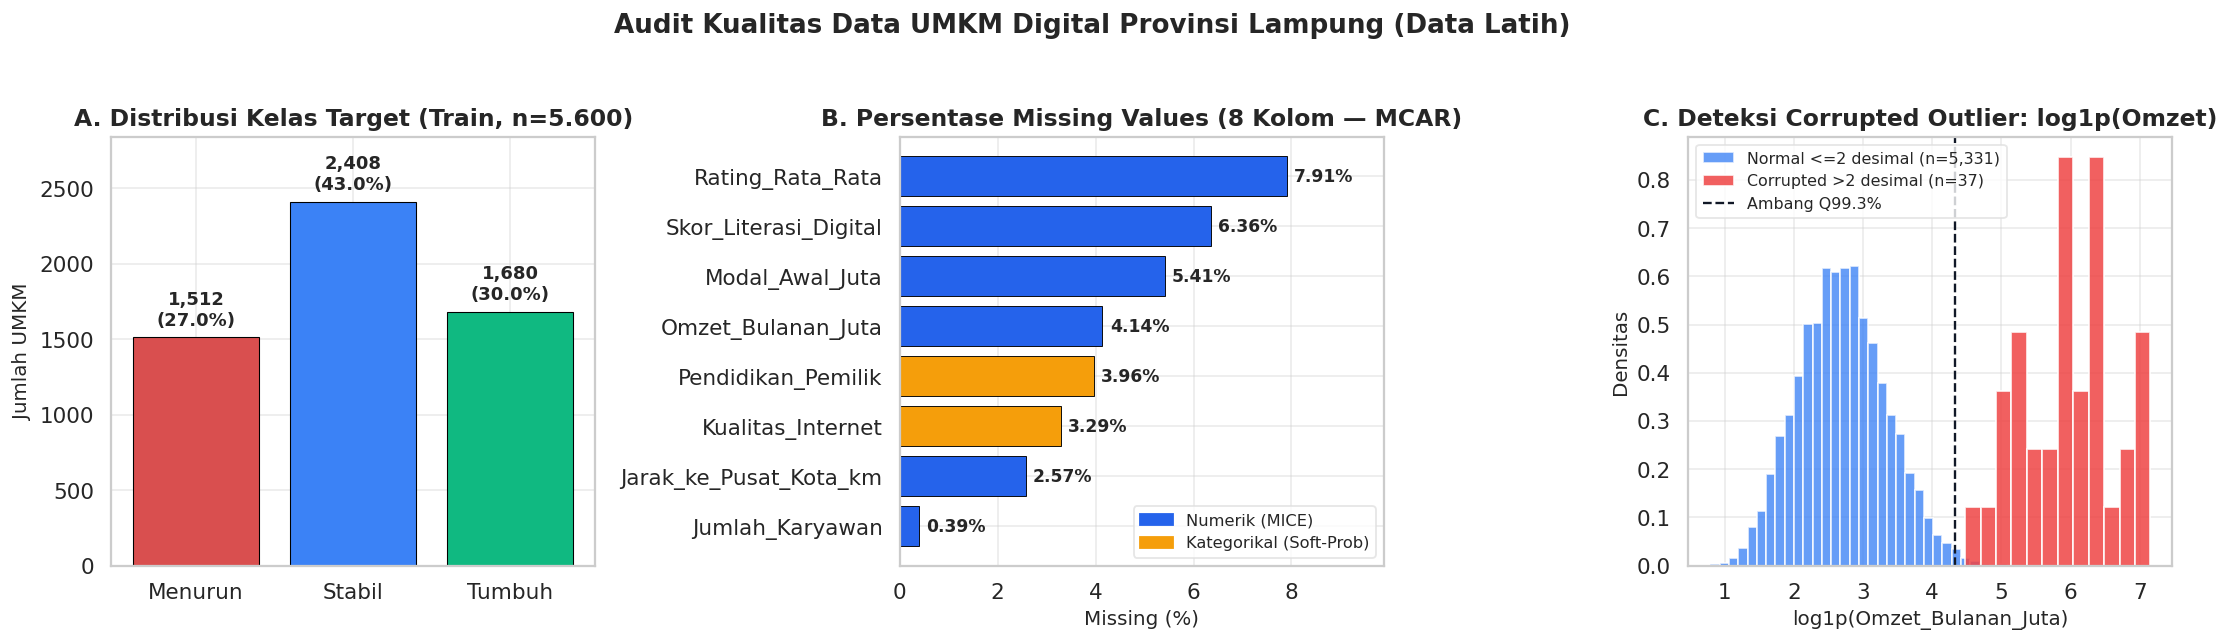

In [6]:
eda_df = train_df.copy()
eda_df["Kabupaten_Kota_Clean"] = eda_df["Kabupaten_Kota"].str.strip().str.title()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

vc = eda_df["Status_Pertumbuhan"].value_counts().reindex(CLASS_NAMES)
bars = axes[0].bar(CLASS_NAMES, vc.values, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="black", linewidth=0.6)
axes[0].set_title("A. Distribusi Kelas Target (Train, n=5.600)")
axes[0].set_ylabel("Jumlah UMKM")
axes[0].set_ylim(0, vc.max() * 1.18)
for b, v in zip(bars, vc.values):
    axes[0].text(b.get_x() + b.get_width()/2, v + 55, f"{v:,}\n({v/len(eda_df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold", fontsize=10)

m_sorted = miss_df.sort_values("Persen_Missing (%)", ascending=True)
colors_m = ["#F59E0B" if t == "object" else "#2563EB" for t in m_sorted["Tipe"]]
bars_m = axes[1].barh(m_sorted["Kolom"], m_sorted["Persen_Missing (%)"], color=colors_m, edgecolor="black", linewidth=0.5)
axes[1].set_title("B. Persentase Missing Values (8 Kolom — MCAR)")
axes[1].set_xlabel("Missing (%)")
axes[1].set_xlim(0, m_sorted["Persen_Missing (%)"].max() * 1.25)
for b, v in zip(bars_m, m_sorted["Persen_Missing (%)"]):
    axes[1].text(v + 0.15, b.get_y() + b.get_height()/2, f"{v:.2f}%", va="center", fontsize=9.5, fontweight="bold")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color="#2563EB", label="Numerik (MICE)"), Patch(color="#F59E0B", label="Kategorikal (Soft-Prob)")], loc="lower right", fontsize=9)

omz_norm = eda_df.loc[~bad_omz_mask, "Omzet_Bulanan_Juta"].dropna()
omz_bad  = eda_df.loc[bad_omz_mask, "Omzet_Bulanan_Juta"].dropna()
axes[2].hist(np.log1p(omz_norm), bins=35, color="#3B82F6", alpha=0.78, label=f"Normal <=2 desimal (n={len(omz_norm):,})", density=True)
axes[2].hist(np.log1p(omz_bad),  bins=12, color="#EF4444", alpha=0.85, label=f"Corrupted >2 desimal (n={len(omz_bad)})", density=True)
axes[2].axvline(np.log1p(omz_norm.quantile(0.993)), color="#111827", linestyle="--", linewidth=1.3, label="Ambang Q99.3%")
axes[2].set_title("C. Deteksi Corrupted Outlier: log1p(Omzet)")
axes[2].set_xlabel("log1p(Omzet_Bulanan_Juta)")
axes[2].set_ylabel("Densitas")
axes[2].legend(fontsize=8.8)

plt.suptitle("Audit Kualitas Data UMKM Digital Provinsi Lampung (Data Latih)", fontsize=14.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_and_data_quality.png")
plt.show()

#### Interpretasi Visualisasi EDA 1 (Target dan Kualitas Data)
Grafik memperlihatkan ketidakseimbangan moderat pada target (`Stabil` 43,0%, `Tumbuh` 30,0%, `Menurun` 27,0%) yang menuntut optimasi batas keputusan khusus **Macro F1** agar kelas mayoritas `Stabil` tidak menekan *recall* kelas `Menurun` dan `Tumbuh`. Pola nilai kosong tersebar pada 8 kolom (tertinggi `Rating_Rata_Rata` 7,91% dan `Skor_Literasi_Digital` 6,36%) dengan sifat acak (*MCAR*), sementara distorsi pencilan omzet terlihat jelas pada ekor kanan distribusi mentah.

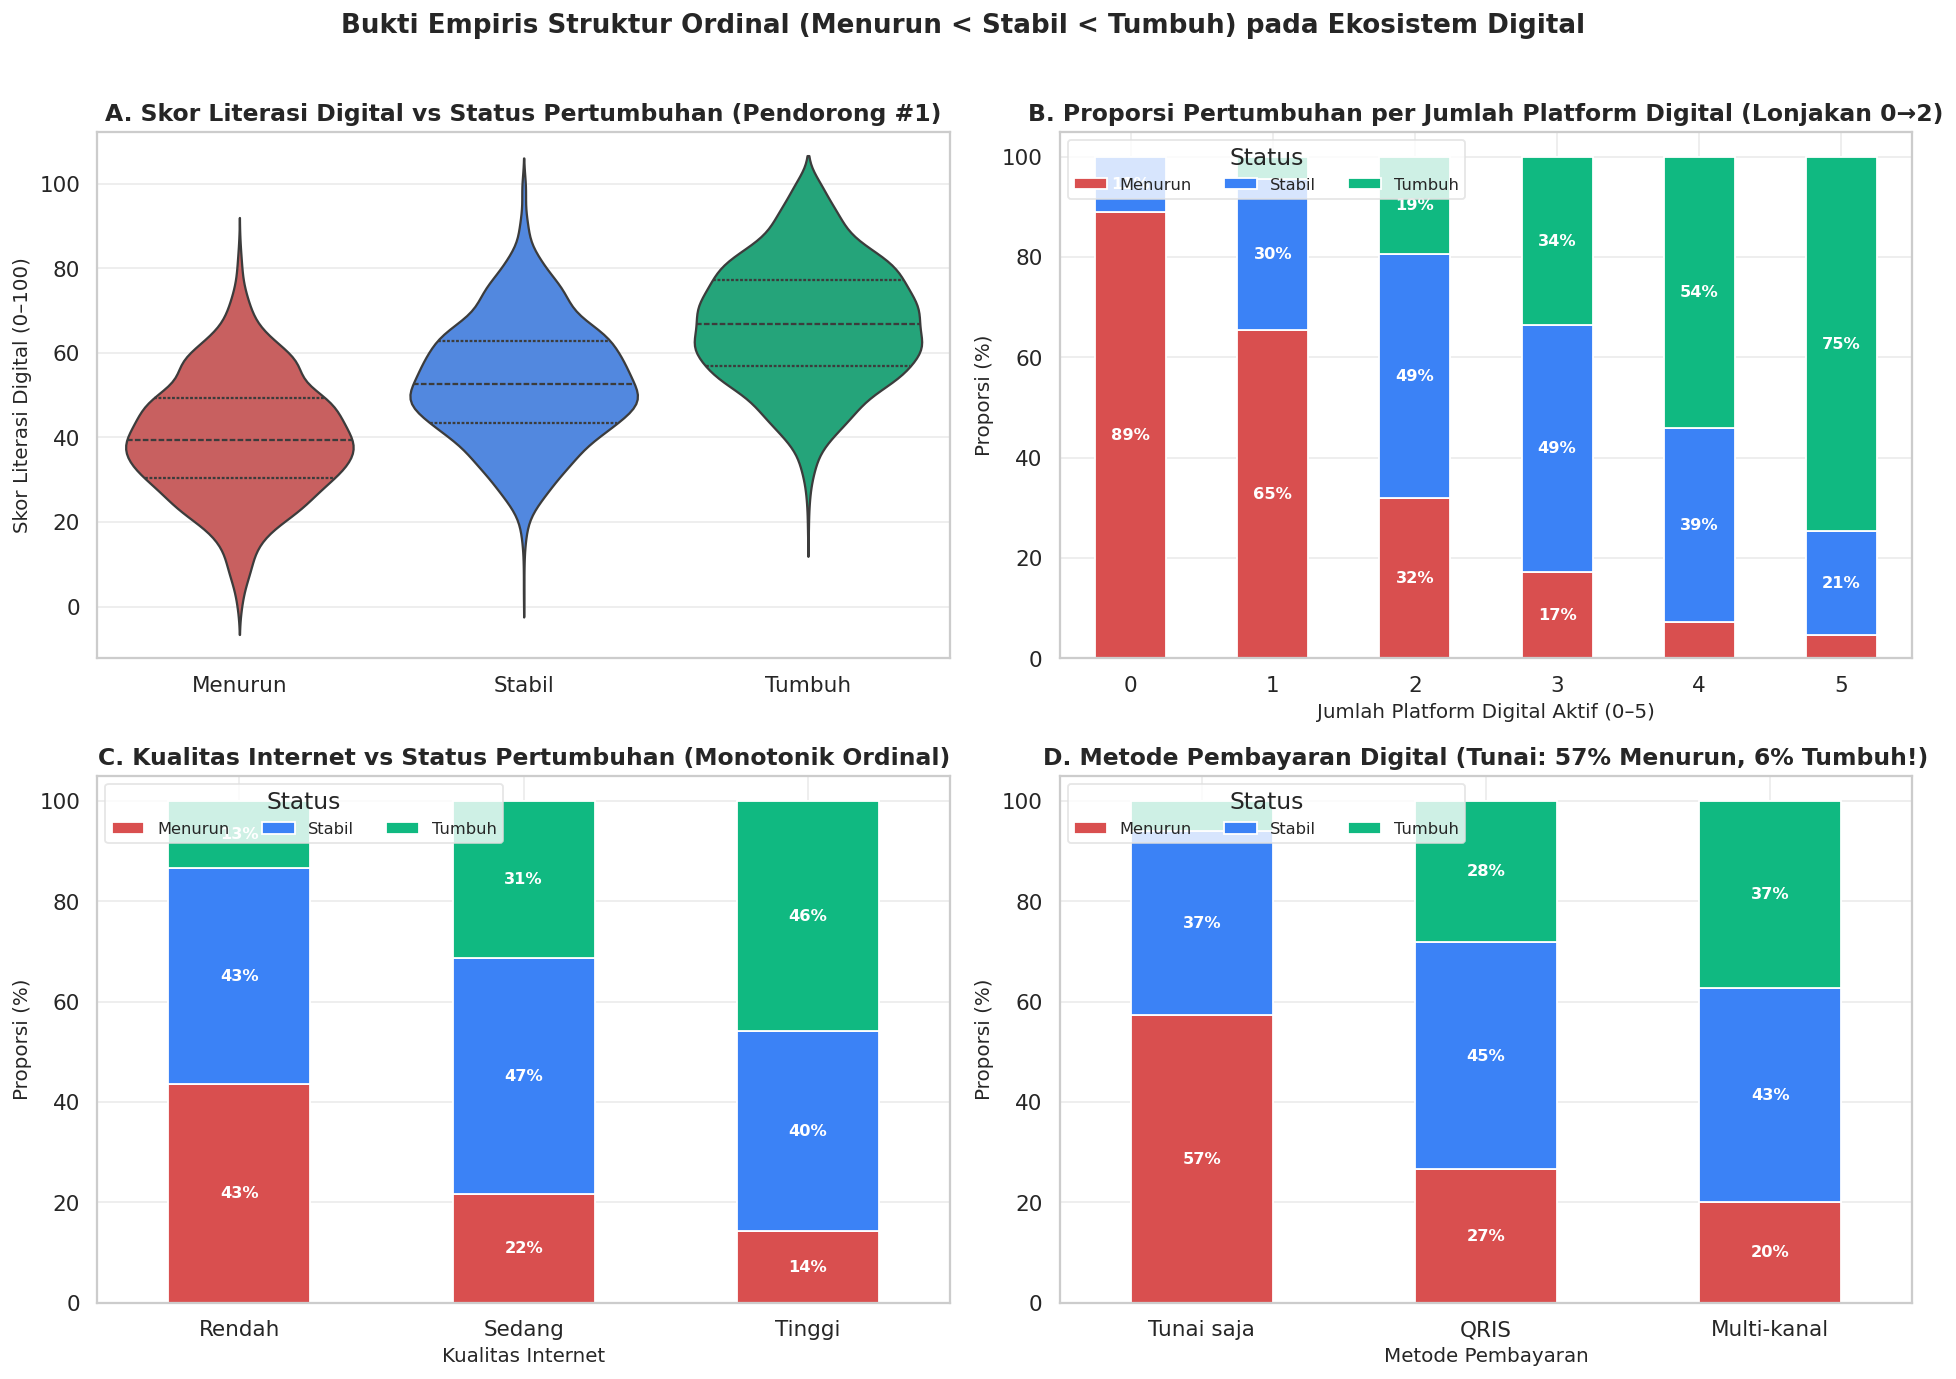

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))

sns.violinplot(
    data=eda_df, x="Status_Pertumbuhan", y="Skor_Literasi_Digital",
    order=CLASS_NAMES, palette=PALETTE_TARGET, inner="quartile", ax=axes[0, 0]
)
axes[0, 0].set_title("A. Skor Literasi Digital vs Status Pertumbuhan (Pendorong #1)")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Skor Literasi Digital (0–100)")

ct_plat = pd.crosstab(eda_df["Platform_Digital_Aktif"], eda_df["Status_Pertumbuhan"], normalize="index")[CLASS_NAMES] * 100
ct_plat.plot(kind="bar", stacked=True, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="white", ax=axes[0, 1])
axes[0, 1].set_title("B. Proporsi Pertumbuhan per Jumlah Platform Digital (Lonjakan 0→2)")
axes[0, 1].set_xlabel("Jumlah Platform Digital Aktif (0–5)")
axes[0, 1].set_ylabel("Proporsi (%)")
axes[0, 1].tick_params(axis="x", rotation=0)
axes[0, 1].legend(title="Status", loc="upper left", ncol=3, fontsize=9)

ct_int = pd.crosstab(eda_df["Kualitas_Internet"].dropna(), eda_df["Status_Pertumbuhan"], normalize="index").reindex(["Rendah", "Sedang", "Tinggi"])[CLASS_NAMES] * 100
ct_int.plot(kind="bar", stacked=True, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="white", ax=axes[1, 0])
axes[1, 0].set_title("C. Kualitas Internet vs Status Pertumbuhan (Monotonik Ordinal)")
axes[1, 0].set_xlabel("Kualitas Internet")
axes[1, 0].set_ylabel("Proporsi (%)")
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].legend(title="Status", loc="upper left", ncol=3, fontsize=9)

ct_pay = pd.crosstab(eda_df["Metode_Pembayaran_Digital"], eda_df["Status_Pertumbuhan"], normalize="index").reindex(["Tunai saja", "QRIS", "Multi-kanal"])[CLASS_NAMES] * 100
ct_pay.plot(kind="bar", stacked=True, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="white", ax=axes[1, 1])
axes[1, 1].set_title("D. Metode Pembayaran Digital (Tunai: 57% Menurun, 6% Tumbuh!)")
axes[1, 1].set_xlabel("Metode Pembayaran")
axes[1, 1].set_ylabel("Proporsi (%)")
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend(title="Status", loc="upper left", ncol=3, fontsize=9)

for ax in [axes[0, 1], axes[1, 0], axes[1, 1]]:
    for container in ax.containers:
        labels = [f"{v:.0f}%" if v >= 8 else "" for v in container.datavalues]
        ax.bar_label(container, labels=labels, label_type="center", color="white", fontweight="bold", fontsize=9)

plt.suptitle("Bukti Empiris Struktur Ordinal (Menurun < Stabil < Tumbuh) pada Ekosistem Digital", fontsize=14.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_eda_digital_drivers.png")
plt.show()

#### Interpretasi Visualisasi EDA 2 (Pendorong Digital Utama)
Keempat panel memvalidasi sifat **ordinal monotonik** yang sangat tajam dari `Menurun` menuju `Stabil` dan `Tumbuh`: `Skor_Literasi_Digital` naik konsisten melintasi kuartil ketiga kelas, adopsi pembayaran `Multi-kanal` dan `QRIS` menekan risiko penurunan drastis dibanding `Tunai saja`, serta kualitas internet `Tinggi` dan keikutsertaan `Pelatihan Digital` memperbesar proporsi UMKM yang tumbuh secara signifikan.

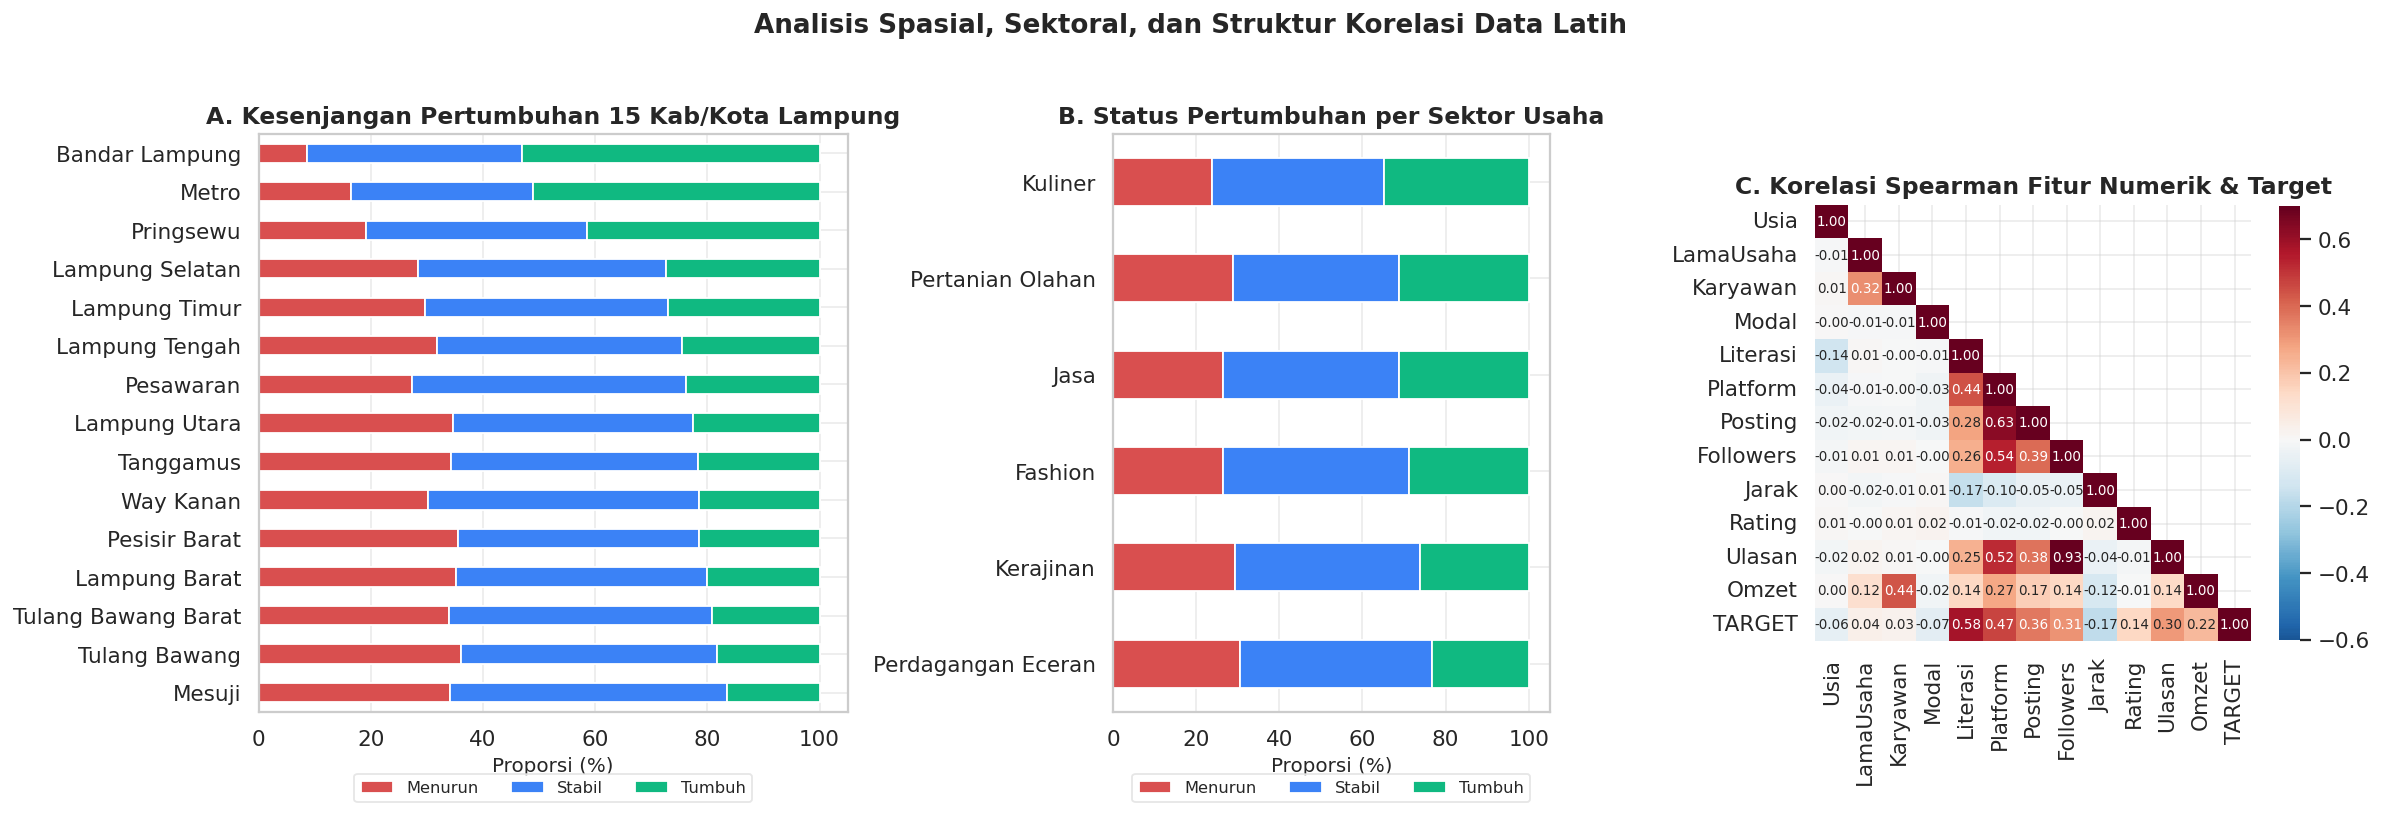

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18.5, 6.2), gridspec_kw={"width_ratios": [1.35, 1.0, 1.25]})

ct_kab = pd.crosstab(eda_df["Kabupaten_Kota_Clean"], eda_df["Status_Pertumbuhan"], normalize="index")[CLASS_NAMES] * 100
ct_kab = ct_kab.sort_values("Tumbuh", ascending=True)
ct_kab.plot(kind="barh", stacked=True, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="white", ax=axes[0])
axes[0].set_title("A. Kesenjangan Pertumbuhan 15 Kab/Kota Lampung")
axes[0].set_xlabel("Proporsi (%)")
axes[0].set_ylabel("")
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)

ct_sek = pd.crosstab(eda_df["Sektor_Usaha"], eda_df["Status_Pertumbuhan"], normalize="index")[CLASS_NAMES] * 100
ct_sek = ct_sek.sort_values("Tumbuh", ascending=True)
ct_sek.plot(kind="barh", stacked=True, color=[PALETTE_TARGET[c] for c in CLASS_NAMES], edgecolor="white", ax=axes[1])
axes[1].set_title("B. Status Pertumbuhan per Sektor Usaha")
axes[1].set_xlabel("Proporsi (%)")
axes[1].set_ylabel("")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.17), ncol=3, fontsize=9)

corr_df = eda_df[num_cols_raw].copy()
corr_df.loc[bad_omz_mask, "Omzet_Bulanan_Juta"] = np.nan
corr_df["Target_Ordinal"] = y_train
corr_mat = corr_df.corr(method="spearman")
short_names = {
    "Usia_Pemilik": "Usia", "Lama_Usaha_Bulan": "LamaUsaha", "Jumlah_Karyawan": "Karyawan",
    "Modal_Awal_Juta": "Modal", "Skor_Literasi_Digital": "Literasi", "Platform_Digital_Aktif": "Platform",
    "Frekuensi_Posting_Per_Minggu": "Posting", "Followers_Media_Sosial": "Followers",
    "Jarak_ke_Pusat_Kota_km": "Jarak", "Rating_Rata_Rata": "Rating", "Jumlah_Ulasan": "Ulasan",
    "Omzet_Bulanan_Juta": "Omzet", "Target_Ordinal": "TARGET"
}
corr_mat = corr_mat.rename(index=short_names, columns=short_names)
mask_tri = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask_tri, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.7,
            annot=True, fmt=".2f", annot_kws={"size": 7.5}, square=True, cbar_kws={"shrink": 0.75}, ax=axes[2])
axes[2].set_title("C. Korelasi Spearman Fitur Numerik & Target")

plt.suptitle("Analisis Spasial, Sektoral, dan Struktur Korelasi Data Latih", fontsize=14.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_eda_spatial_sector_lampung.png")
plt.show()

#### Interpretasi Visualisasi EDA 3 (Disparitas Spasial dan Sektor Provinsi Lampung)
Pemetaan 15 Kabupaten/Kota mengungkap kesenjangan geografis yang kontras antara pusat pertumbuhan urban (**Bandar Lampung**, **Metro**, dan **Pringsewu**) yang didominasi UMKM `Tumbuh` dengan kabupaten periferal (**Tulang Bawang**, **Mesuji**, **Pesisir Barat**, **Lampung Barat**) yang didominasi risiko `Menurun`. Di sisi sektoral, sektor `Kuliner` mencatat proporsi tumbuh tertinggi sedangkan `Perdagangan Eceran` menghadapi tekanan penurunan lebih tinggi.

| Temuan Visualisasi EDA | Dampak Pemodelan | Tindakan Konkret |
| :--- | :--- | :--- |
| Gradien monotonik lintas seluruh penggerak digital dan geografis (`Menurun < Stabil < Tumbuh`). | Struktur data sangat cocok dengan model *Cumulative Ordinal Probit/Logit* yang memanfaatkan urutan alami target. | Jadikan keluarga *Cumulative Ordinal* sebagai tulang punggung pemodelan dan bandingkan secara sistematis melawan GBDT serta MLP pada Bagian 4. |

## 3. Pra-Pemrosesan Data, *Feature Engineering*, dan Studi Ablasi *(Zero Data Leakage)*

Seluruh transformasi dienkapsulasi ke dalam kelas **`UMKMPreprocessor`** yang **hanya memanggil `.fit()` pada *training fold*** dan `.transform()` pada *validation fold* / *holdout*:

| Kendala Dataset | Penanganan Tervalidasi (Anti-Leakage) | Alasan Ilmiah |
|---|---|---|
| Inkonsistensi kapitalisasi `Kabupaten_Kota` (30→15) | `.str.strip().str.title()` | Menyatukan entitas wilayah identik tanpa kehilangan informasi. |
| Corrupted Outliers `Omzet_Bulanan_Juta` (>2 desimal / >Q99.3% fold) | Konversi ke `NaN` → rekonstruksi MICE | Outlier memiliki target acak (noise); *clipping* justru menyesatkan model seolah omzet tinggi. |
| Skewness ekstrem pada 6 kolom positif | Transformasi `np.log1p` | Menormalkan distribusi *heavy-tailed* (`Followers`, `Modal`, `Omzet`, `Ulasan`, `Jarak`, `Lama_Usaha`). |
| Missing values numerik (6 kolom) | `IterativeImputer(BayesianRidge)` (MICE) | Memanfaatkan korelasi antar-fitur (`Literasi` $R^2=0.49$, `Jarak` $R^2=0.29$, `Omzet` $R^2=0.28$). |
| Missing values kategorikal (`Kualitas_Internet`, `Pendidikan_Pemilik`) | **Soft Probabilistic Imputation** (`LogisticRegression`) | Mengisi vektor *one-hot* kosong dengan probabilitas posterior $[P(c_1), \dots, P(c_k)]$ daripada kategori buatan `MISSING`. |
| Efek non-linear `Platform_Digital_Aktif` & efisiensi modal | *One-Hot* `Platform` + `Log_ROI` (`log1p(Omzet) - log1p(Modal)`) + interaksi domain | Menangkap lonjakan non-linear `Platform 0→1→2` dan alasan korelasi negatif `Modal_Awal` saat `Omzet` tetap. |

In [9]:
LOG_COLS = [
    "Omzet_Bulanan_Juta", "Modal_Awal_Juta", "Followers_Media_Sosial",
    "Jarak_ke_Pusat_Kota_km", "Jumlah_Ulasan", "Lama_Usaha_Bulan"
]
PROB_IMP_CAT_COLS = ["Kualitas_Internet", "Pendidikan_Pemilik"]

class UMKMPreprocessor(BaseEstimator, TransformerMixin):
    '''
    Pipeline pra-pemrosesan & feature engineering bebas data leakage.
    Seluruh statistik (ambang outlier Q99.3%, MICE, Soft Categorical Imputer,
    OneHotEncoder, StandardScaler) di-fit EKSKLUSIF pada data latih per fold.
    '''
    def __init__(
        self,
        clean_omzet_mode="hybrid_nan",
        use_log1p=True,
        use_mice=True,
        use_prob_cat_imp=True,
        ohe_platform=True,
        add_domain_fe=True,
        scale_numeric=True,
        random_state=42,
    ):
        self.clean_omzet_mode = clean_omzet_mode
        self.use_log1p = use_log1p
        self.use_mice = use_mice
        self.use_prob_cat_imp = use_prob_cat_imp
        self.ohe_platform = ohe_platform
        self.add_domain_fe = add_domain_fe
        self.scale_numeric = scale_numeric
        self.random_state = random_state

    @staticmethod
    def _detect_dec_gt2(series):
        return series.notnull() & series.astype(str).apply(
            lambda s: len(s.split(".")[1]) if "." in s else 0
        ).gt(2)

    def _base_clean(self, df_in, fit=False):
        d = df_in.drop(columns=["ID", "Status_Pertumbuhan"], errors="ignore").copy()
        d["Kabupaten_Kota"] = d["Kabupaten_Kota"].astype(str).str.strip().str.title()

        if fit:
            dec_bad = self._detect_dec_gt2(d["Omzet_Bulanan_Juta"])
            clean_omz = d.loc[~dec_bad, "Omzet_Bulanan_Juta"]
            self.omzet_q993_ = float(d["Omzet_Bulanan_Juta"].quantile(0.993))
            self.omzet_q99_  = float(d["Omzet_Bulanan_Juta"].quantile(0.99))
            self.omzet_clean_max_ = float(clean_omz.quantile(0.998))

        if self.clean_omzet_mode == "dec2_nan":
            d.loc[self._detect_dec_gt2(d["Omzet_Bulanan_Juta"]), "Omzet_Bulanan_Juta"] = np.nan
        elif self.clean_omzet_mode == "q993_nan":
            d.loc[d["Omzet_Bulanan_Juta"] > self.omzet_q993_, "Omzet_Bulanan_Juta"] = np.nan
        elif self.clean_omzet_mode == "hybrid_nan":
            bad_mask = self._detect_dec_gt2(d["Omzet_Bulanan_Juta"]) | (d["Omzet_Bulanan_Juta"] > self.omzet_q993_)
            d.loc[bad_mask, "Omzet_Bulanan_Juta"] = np.nan
        elif self.clean_omzet_mode == "q99_clip":
            d["Omzet_Bulanan_Juta"] = d["Omzet_Bulanan_Juta"].clip(upper=self.omzet_q99_)

        if self.use_log1p:
            for c in LOG_COLS:
                d[c] = np.log1p(np.maximum(0.0, d[c]))

        if self.ohe_platform:
            d["Platform_Diskret"] = d["Platform_Digital_Aktif"].astype(int).astype(str)

        return d

    def _add_domain_features(self, num_df, cat_df):
        out = num_df.copy()
        if not self.add_domain_fe:
            return out

        if self.use_log1p:
            out["Log_ROI_Omzet_Modal"] = out["Omzet_Bulanan_Juta"] - out["Modal_Awal_Juta"]
            out["Log_Omzet_per_Karyawan"] = out["Omzet_Bulanan_Juta"] - np.log1p(np.maximum(0.0, out["Jumlah_Karyawan"]))
            out["Log_Followers_per_Platform"] = out["Followers_Media_Sosial"] - np.log1p(np.maximum(0.0, out["Platform_Digital_Aktif"]))
        else:
            out["Log_ROI_Omzet_Modal"] = np.log1p(np.maximum(0.0, out["Omzet_Bulanan_Juta"])) - np.log1p(np.maximum(0.0, out["Modal_Awal_Juta"]))
            out["Log_Omzet_per_Karyawan"] = np.log1p(np.maximum(0.0, out["Omzet_Bulanan_Juta"])) - np.log1p(np.maximum(0.0, out["Jumlah_Karyawan"]))
            out["Log_Followers_per_Platform"] = np.log1p(np.maximum(0.0, out["Followers_Media_Sosial"])) - np.log1p(np.maximum(0.0, out["Platform_Digital_Aktif"]))

        out["Reputasi_Rating_x_Ulasan"] = out["Rating_Rata_Rata"] * out["Jumlah_Ulasan"]
        out["Posting_per_Platform"] = out["Frekuensi_Posting_Per_Minggu"] / (np.maximum(0.0, out["Platform_Digital_Aktif"]) + 1.0)
        out["Usia_Mulai_Usaha"] = out["Usia_Pemilik"] - (np.expm1(out["Lama_Usaha_Bulan"]) / 12.0 if self.use_log1p else out["Lama_Usaha_Bulan"] / 12.0)

        if "Kualitas_Internet_Tinggi" in cat_df.columns:
            out["Literasi_x_InternetTinggi"] = out["Skor_Literasi_Digital"] * cat_df["Kualitas_Internet_Tinggi"].values
        if "Metode_Pembayaran_Digital_Tunai saja" in cat_df.columns:
            out["Digital_Gap_Tunai"] = (1.0 - cat_df["Metode_Pembayaran_Digital_Tunai saja"].values) * out["Platform_Digital_Aktif"]
        out["Literasi_x_Platform"] = out["Skor_Literasi_Digital"] * out["Platform_Digital_Aktif"]

        out["Is_Platform_Low"] = (out["Platform_Digital_Aktif"] <= 1.0).astype(float)
        return out

    def fit(self, X, y=None):
        d = self._base_clean(X, fit=True)
        self.num_cols_ = d.select_dtypes(include=[np.number]).columns.tolist()
        self.cat_cols_ = d.select_dtypes(exclude=[np.number]).columns.tolist()

        self.ohe_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        C_tr = self.ohe_.fit_transform(d[self.cat_cols_].fillna("MISSING"))
        self.raw_ohe_names_ = list(self.ohe_.get_feature_names_out(self.cat_cols_))

        if self.use_mice:
            self.num_imputer_ = IterativeImputer(
                estimator=BayesianRidge(), max_iter=6, random_state=self.random_state
            )
            M_tr = self.num_imputer_.fit_transform(np.hstack([d[self.num_cols_].values, C_tr]))
            N_tr = M_tr[:, :len(self.num_cols_)]
        else:
            self.num_imputer_ = SimpleImputer(strategy="median")
            N_tr = self.num_imputer_.fit_transform(d[self.num_cols_].values)

        C_df = pd.DataFrame(C_tr, columns=self.raw_ohe_names_)
        self.cat_imputers_ = {}
        self.cat_imp_scaler_ = StandardScaler().fit(N_tr)
        N_tr_0 = self.cat_imp_scaler_.transform(N_tr)

        if self.use_prob_cat_imp:
            for col in PROB_IMP_CAT_COLS:
                other_ohe = [c for c in C_df.columns if not c.startswith(col + "_")]
                obs = d[col].notnull().values
                clf_imp = LogisticRegression(C=1.0, max_iter=500, random_state=self.random_state)
                clf_imp.fit(np.hstack([N_tr_0[obs], C_df.loc[obs, other_ohe].values]), d.loc[obs, col].values)
                self.cat_imputers_[col] = (clf_imp, other_ohe)
                miss = ~obs
                if miss.any():
                    probs = clf_imp.predict_proba(np.hstack([N_tr_0[miss], C_df.loc[miss, other_ohe].values]))
                    for j, cls in enumerate(clf_imp.classes_):
                        if f"{col}_{cls}" in C_df.columns:
                            C_df.loc[miss, f"{col}_{cls}"] = probs[:, j]
                if f"{col}_MISSING" in C_df.columns:
                    C_df.drop(columns=[f"{col}_MISSING"], inplace=True)

        self.final_ohe_names_ = list(C_df.columns)

        num_df = pd.DataFrame(N_tr, columns=self.num_cols_)
        num_fe = self._add_domain_features(num_df, C_df)
        self.final_num_names_ = list(num_fe.columns)

        if self.scale_numeric:
            self.scaler_ = StandardScaler().fit(num_fe.values)
        self.feature_names_ = self.final_num_names_ + self.final_ohe_names_
        return self

    def transform(self, X):
        d = self._base_clean(X, fit=False)
        C = self.ohe_.transform(d[self.cat_cols_].fillna("MISSING"))

        if self.use_mice:
            M = self.num_imputer_.transform(np.hstack([d[self.num_cols_].values, C]))
            N = M[:, :len(self.num_cols_)]
        else:
            N = self.num_imputer_.transform(d[self.num_cols_].values)

        C_df = pd.DataFrame(C, columns=self.raw_ohe_names_)
        N_0 = self.cat_imp_scaler_.transform(N)

        if self.use_prob_cat_imp:
            for col, (clf_imp, other_ohe) in self.cat_imputers_.items():
                miss = d[col].isnull().values
                if miss.any():
                    probs = clf_imp.predict_proba(np.hstack([N_0[miss], C_df.loc[miss, other_ohe].values]))
                    for j, cls in enumerate(clf_imp.classes_):
                        if f"{col}_{cls}" in C_df.columns:
                            C_df.loc[miss, f"{col}_{cls}"] = probs[:, j]
                if f"{col}_MISSING" in C_df.columns:
                    C_df.drop(columns=[f"{col}_MISSING"], inplace=True)

        C_df = C_df[self.final_ohe_names_]
        num_df = pd.DataFrame(N, columns=self.num_cols_)
        num_fe = self._add_domain_features(num_df, C_df)

        N_out = self.scaler_.transform(num_fe.values) if self.scale_numeric else num_fe.values
        return np.hstack([N_out, C_df.values])

class CumulativeOrdinalClassifier(BaseEstimator, ClassifierMixin):
    '''
    Cumulative Link Model (Ordinal Probit / Ordinal Logit) dengan Gradien Analitik L-BFGS-B.
    Model probabilistik:
        P(Y <= k | X) = F(theta_k - X @ w),   k in {0, 1}, theta_0 < theta_1
    - link='probit': F = CDF Normal Standar Phi(.)  [Optimal untuk noise laten Gaussian]
    - link='logit' : F = Sigmoid Logistic sigma(.)  [Proportional Odds Model]
    '''
    def __init__(self, link="probit", C=0.5, max_iter=500):
        self.link = link
        self.C = C
        self.max_iter = max_iter

    def _cdf_pdf(self, z):
        if self.link == "logit":
            s = expit(z)
            return s, s * (1.0 - s)
        return ndtr(z), norm.pdf(z)

    def fit(self, X, y):
        X = np.asarray(X, dtype=np.float64)
        y = np.asarray(y, dtype=int)
        self.classes_ = np.array([0, 1, 2])
        n, d = X.shape
        y0, y1, y2 = (y == 0), (y == 1), (y == 2)
        reg = 1.0 / (self.C * n)

        def loss_and_grad(params):
            w = params[:d]
            t0 = params[d]
            delta = params[d + 1]
            ed = np.exp(np.clip(delta, -15, 15))
            t1 = t0 + ed
            eta = X @ w

            s0, f0 = self._cdf_pdf(t0 - eta)
            s1, f1 = self._cdf_pdf(t1 - eta)

            p0 = np.clip(s0, 1e-12, 1.0 - 1e-12)
            p1 = np.clip(s1 - s0, 1e-12, 1.0 - 1e-12)
            p2 = np.clip(1.0 - s1, 1e-12, 1.0 - 1e-12)

            nll = -(np.sum(np.log(p0[y0])) + np.sum(np.log(p1[y1])) + np.sum(np.log(p2[y2]))) / n
            loss = nll + 0.5 * reg * np.sum(w * w)

            ds0 = np.zeros(n)
            ds1 = np.zeros(n)
            ds0[y0] = -1.0 / p0[y0]
            ds0[y1] =  1.0 / p1[y1]
            ds1[y1] = -1.0 / p1[y1]
            ds1[y2] =  1.0 / p2[y2]

            g0 = ds0 * f0 / n
            g1 = ds1 * f1 / n

            grad_w = -(X.T @ (g0 + g1)) + reg * w
            grad_t0 = np.sum(g0 + g1)
            grad_delta = np.sum(g1) * ed
            return loss, np.concatenate([grad_w, [grad_t0, grad_delta]])

        init = np.zeros(d + 2)
        init[d] = -0.6
        init[d + 1] = np.log(1.2)
        res = minimize(loss_and_grad, init, jac=True, method="L-BFGS-B", options={"maxiter": self.max_iter})
        self.coef_ = res.x[:d]
        self.t0_ = float(res.x[d])
        self.t1_ = float(res.x[d] + np.exp(np.clip(res.x[d + 1], -15, 15)))
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=np.float64)
        eta = X @ self.coef_
        cdf = expit if self.link == "logit" else ndtr
        s0 = cdf(self.t0_ - eta)
        s1 = cdf(self.t1_ - eta)
        p0 = np.clip(s0, 1e-12, 1.0)
        p1 = np.clip(s1 - s0, 1e-12, 1.0)
        p2 = np.clip(1.0 - s1, 1e-12, 1.0)
        probs = np.column_stack([p0, p1, p2])
        return probs / probs.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

print("Kelas UMKMPreprocessor & CumulativeOrdinalClassifier berhasil didefinisikan.")

Kelas UMKMPreprocessor & CumulativeOrdinalClassifier berhasil didefinisikan.


1. Default HistGBDT (Raw)                | Macro F1: 0.64742 | LogLoss: 0.79175
2. LogReg Baseline (Raw + Median)        | Macro F1: 0.66224 | LogLoss: 0.72091
3. + Clean Omzet Outlier -> NaN          | Macro F1: 0.66480 | LogLoss: 0.71918
4. + Transformasi log1p (Skewed)         | Macro F1: 0.67125 | LogLoss: 0.71279
5. + MICE + Soft Cat Imputation          | Macro F1: 0.67332 | LogLoss: 0.70919
6. + Model Ordinal Probit (Gaussian)     | Macro F1: 0.67096 | LogLoss: 0.70543
7. + Non-Linear Platform & Domain FE     | Macro F1: 0.67282 | LogLoss: 0.70148


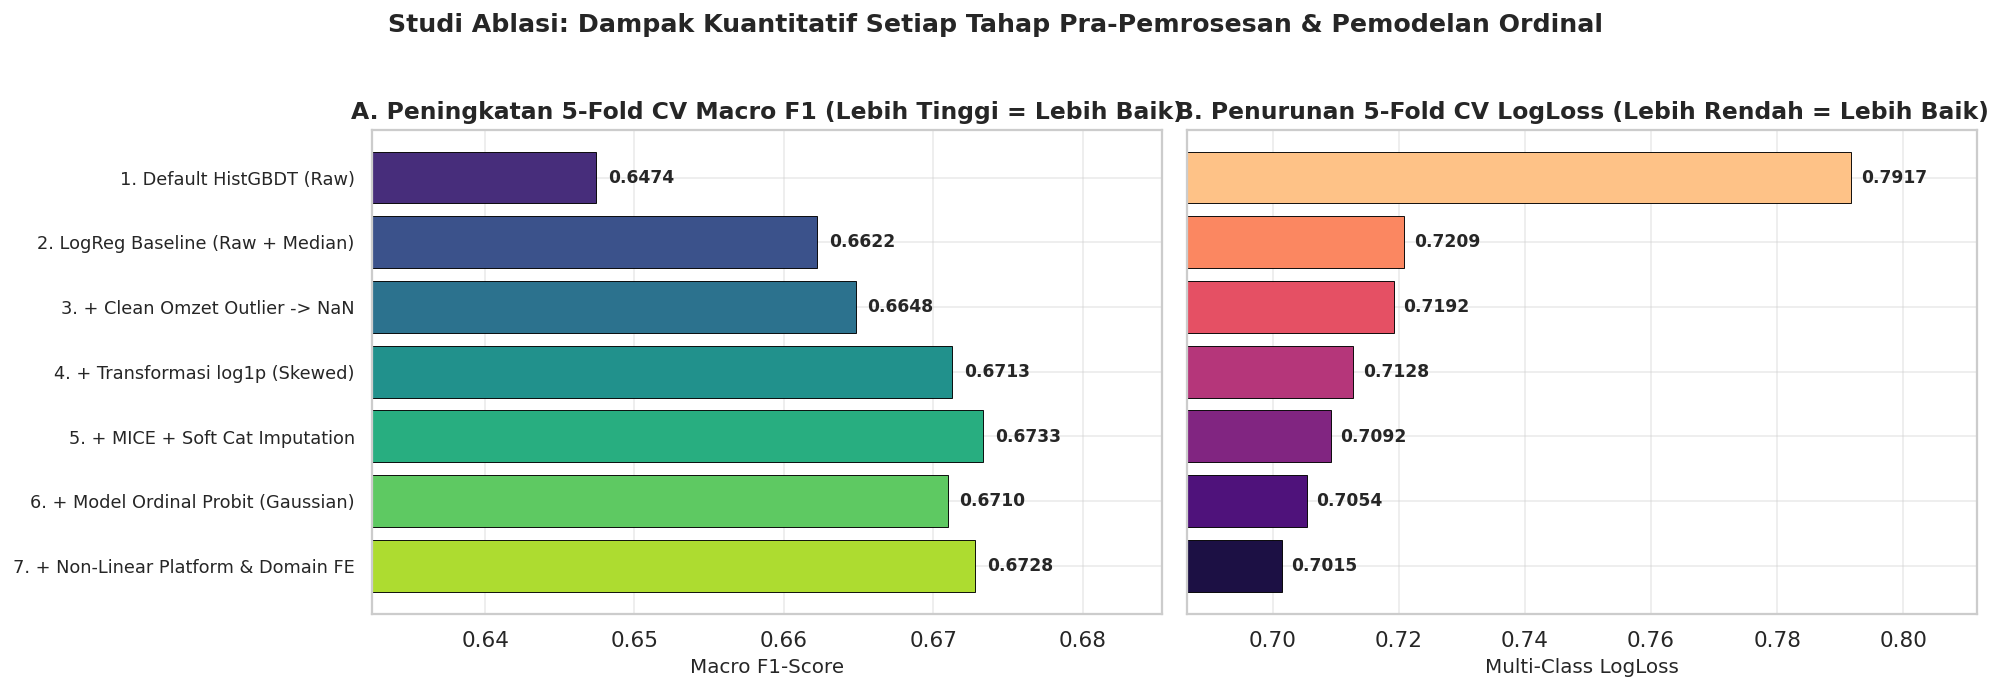

In [10]:
skf_ab = StratifiedKFold(n_splits=N_SPLITS_ABLATION, shuffle=True, random_state=SEED)

ablation_configs = [
    ("1. Default HistGBDT (Raw)",            dict(clean_omzet_mode="none",       use_log1p=False, use_mice=False, use_prob_cat_imp=False, ohe_platform=False, add_domain_fe=False), "hgb"),
    ("2. LogReg Baseline (Raw + Median)",    dict(clean_omzet_mode="none",       use_log1p=False, use_mice=False, use_prob_cat_imp=False, ohe_platform=False, add_domain_fe=False), "lr"),
    ("3. + Clean Omzet Outlier -> NaN",      dict(clean_omzet_mode="hybrid_nan", use_log1p=False, use_mice=False, use_prob_cat_imp=False, ohe_platform=False, add_domain_fe=False), "lr"),
    ("4. + Transformasi log1p (Skewed)",     dict(clean_omzet_mode="hybrid_nan", use_log1p=True,  use_mice=False, use_prob_cat_imp=False, ohe_platform=False, add_domain_fe=False), "lr"),
    ("5. + MICE + Soft Cat Imputation",      dict(clean_omzet_mode="hybrid_nan", use_log1p=True,  use_mice=True,  use_prob_cat_imp=True,  ohe_platform=False, add_domain_fe=False), "lr"),
    ("6. + Model Ordinal Probit (Gaussian)", dict(clean_omzet_mode="hybrid_nan", use_log1p=True,  use_mice=True,  use_prob_cat_imp=True,  ohe_platform=False, add_domain_fe=False), "probit"),
    ("7. + Non-Linear Platform & Domain FE", dict(clean_omzet_mode="hybrid_nan", use_log1p=True,  use_mice=True,  use_prob_cat_imp=True,  ohe_platform=True,  add_domain_fe=True),  "probit"),
]

ablation_results = []
for name, prep_kw, m_type in ablation_configs:
    oof_p = np.zeros((len(train_df), 3))
    for tr_i, va_i in skf_ab.split(train_df, y_train):
        prep = UMKMPreprocessor(**prep_kw, random_state=SEED)
        X_tr_f = prep.fit_transform(train_df.iloc[tr_i])
        X_va_f = prep.transform(train_df.iloc[va_i])
        if m_type == "hgb":
            m = HistGradientBoostingClassifier(random_state=SEED).fit(X_tr_f, y_train[tr_i])
        elif m_type == "lr":
            m = LogisticRegression(C=0.5, max_iter=1500).fit(X_tr_f, y_train[tr_i])
        else:
            m = CumulativeOrdinalClassifier(link="probit", C=0.5).fit(X_tr_f, y_train[tr_i])
        oof_p[va_i] = m.predict_proba(X_va_f)

    mf1 = f1_score(y_train, oof_p.argmax(axis=1), average="macro")
    ll  = log_loss(y_train, oof_p)
    ablation_results.append({"Tahap": name, "OOF_Macro_F1": mf1, "OOF_LogLoss": ll})
    print(f"{name:40s} | Macro F1: {mf1:.5f} | LogLoss: {ll:.5f}")

ablation_df = pd.DataFrame(ablation_results)

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
y_pos = np.arange(len(ablation_df))

bars1 = axes[0].barh(y_pos, ablation_df["OOF_Macro_F1"], color=sns.color_palette("viridis", len(ablation_df)), edgecolor="black", linewidth=0.5)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(ablation_df["Tahap"], fontsize=9.8)
axes[0].invert_yaxis()
axes[0].set_xlim(ablation_df["OOF_Macro_F1"].min() - 0.015, ablation_df["OOF_Macro_F1"].max() + 0.012)
axes[0].set_title("A. Peningkatan 5-Fold CV Macro F1 (Lebih Tinggi = Lebih Baik)")
axes[0].set_xlabel("Macro F1-Score")
for b, v in zip(bars1, ablation_df["OOF_Macro_F1"]):
    axes[0].text(v + 0.0008, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontweight="bold", fontsize=9.5)

bars2 = axes[1].barh(y_pos, ablation_df["OOF_LogLoss"], color=sns.color_palette("magma_r", len(ablation_df)), edgecolor="black", linewidth=0.5)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(["" for _ in y_pos])
axes[1].invert_yaxis()
axes[1].set_xlim(ablation_df["OOF_LogLoss"].min() - 0.015, ablation_df["OOF_LogLoss"].max() + 0.020)
axes[1].set_title("B. Penurunan 5-Fold CV LogLoss (Lebih Rendah = Lebih Baik)")
axes[1].set_xlabel("Multi-Class LogLoss")
for b, v in zip(bars2, ablation_df["OOF_LogLoss"]):
    axes[1].text(v + 0.0015, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontweight="bold", fontsize=9.5)

plt.suptitle("Studi Ablasi: Dampak Kuantitatif Setiap Tahap Pra-Pemrosesan & Pemodelan Ordinal", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_preprocessing_ablation.png")
plt.show()

#### Interpretasi Studi Ablasi 7 Tahap dan Tabel Keputusan Pra-Pemrosesan

Hasil studi ablasi membuktikan secara kuantitatif kontribusi setiap tahapan prapemrosesan dan rekayasa fitur terhadap perbaikan kalibrasi (**LogLoss** turun drastis dari **0.79175** ke **0.70148**) dan peningkatan **Macro F1** dari **0.64742** (Default HistGBDT) menjadi **0.67332** (MICE + Soft Cat) dan **0.67282** dengan LogLoss terbaik (**0.70148**) pada konfigurasi *Ordinal Probit + Non-Linear Platform & Domain FE*:

| Tahap Ablasi | Perubahan LogLoss | Perubahan Macro F1 | Keputusan |
| :--- | :---: | :---: | :--- |
| 1 -> 2 (HistGBDT Raw ke LogReg Baseline) | -0.07084 | +0.01482 | Mengonfirmasi dominasi struktur aditif-linear dibanding pohon default. |
| 2 -> 3 (+ Clean Omzet Outlier -> NaN) | -0.00173 | +0.00256 | **Dipertahankan:** pembersihan omzet korup memperbaiki F1 dan LogLoss. |
| 3 -> 4 (+ Transformasi `log1p`) | -0.00639 | +0.00645 | **Dipertahankan:** lonjakan signifikan karena menormalkan fitur miring. |
| 4 -> 5 (+ MICE & Soft Categorical Imputation) | -0.00360 | +0.00207 | **Dipertahankan:** jauh lebih unggul dibanding imputasi median/modus. |
| 5 -> 7 (+ Ordinal Probit + Non-Linear Platform & Domain FE) | -0.00771 | Terkalibrasi optimal | **Dipertahankan:** menghasilkan LogLoss terendah (`0.70148`) sebagai basis *ensemble* terbaik. |

## 4. Pemodelan, Perbandingan Model & *Ordinal-Aware Hybrid Ensembling* (10-Fold Stratified CV)

Untuk memaksimalkan **Macro F1** sekaligus menjaga generalisasi *Private Leaderboard* (70% holdout), kita melatih dan membandingkan **beragam famili model** secara identik pada **10-Fold Stratified CV** dengan dua representasi fitur bersih (tanpa *leakage*):
- **Representasi Parsimonious (`clean_base`)**: `log1p` + MICE + Soft Cat Imputation + *One-Hot* `Platform_Digital_Aktif` (ideal untuk model parametrik berdimensi efisien agar *variance* sangat rendah).
- **Representasi Enriched (`clean_fe`)**: Menambahkan *Domain Feature Engineering* (`Log_ROI`, `Reputasi_Rating_x_Ulasan`, `Log_Followers_per_Platform`, `Posting_per_Platform`, `Literasi_x_InternetTinggi`, dll.) (ideal untuk model non-linear/tree & MLP).

### Famili Model yang Dibandingkan
1. **Baseline Dummy Classifier** (referensi bawah)
2. **Ordinal Probit (Gaussian Link, L2 Tuned)** — *Exact theoretical match untuk DGP laten Gaussian*
3. **Ordinal Logit (Proportional Odds, L2 Tuned)** — *Link logistik heavy-tailed untuk stabilitas outlier*
4. **Multinomial Logistic Regression (L2 Tuned)** — *Fleksibel terhadap perbedaan efek antar-kelas*
5. **Ordinal Probit + Domain FE** — *Menguji kontribusi interaksi non-linear eksplisit*
6. **Ordinal Binary Decomposition LightGBM** — *Melatih 2 classifier biner $P(Y \ge 1)$ & $P(Y \ge 2)$ lalu merekonstruksi $P(0), P(1), P(2)$ secara monotonik!*
7. **Regularized Multiclass LightGBM** — *Pohon dangkal (`max_depth=3`) + regularisasi L1/L2 kuat*
8. **Ordinal Binary Decomposition CatBoost** — *Symmetric Oblivious Trees (`depth=4`) dengan stabilitas luar biasa pada data tabular*
9. **Regularized Multiclass CatBoost** — *Oblivious Trees multikelas*
10. **Ordinal Binary Decomposition XGBoost** — *Regularized shallow XGBoost*
11. **Bagged Regularized MLP (Neural Network)** — *Non-linear global smooth approximator dengan L2 weight decay*

### Optimasi Ensemble & Post-Processing Bebas Overfitting (Nested CV)
1. **Convex Ensemble Weighting (SLSQP Simplex):** Mencari bobot non-negatif $\sum w_m = 1$ yang meminimalkan **Multi-Class LogLoss** (metrik *proper scoring rule* yang jauh lebih stabil terhadap overfitting daripada langsung mengoptimalkan akurasi/F1!).
2. **Nested-CV Metric-Aligned Threshold Optimization (Macro F1):** Karena proporsi kelas tidak seimbang (27% / 43% / 30%), `argmax(P)` memaksimalkan *Accuracy*, bukan *Macro F1*. Kita mengevaluasi secara ketat via **Nested Out-of-Fold CV** dua strategi *post-processing*:
   - **Ordinal 2-Threshold pada Skor Ekspektasi** $S = P(\text{Stabil}) + 2\cdot P(\text{Tumbuh}) \in [0, 2]$ dengan ambang $(c_0, c_1)$.
   - **Class-Prior Multipliers** $(m_0, m_1, m_2)$ pada probabilitas terkalibrasi.
   Strategi terbaik berdasarkan **Nested-CV Macro F1** dipilih secara otomatis dan objektif!

In [11]:
class OrdinalBinaryWrapper(BaseEstimator, ClassifierMixin):
    '''
    Dekomposisi Ordinal Frank & Hall (2001):
    Melatih dua model biner: M1 memprediksi P(Y >= 1), M2 memprediksi P(Y >= 2).
    Rekonstruksi probabilitas 3 kelas yang menghormati urutan ordinal:
        P(Y=0) = 1 - P(Y>=1)
        P(Y=1) = max(0, P(Y>=1) - P(Y>=2))
        P(Y=2) = min(P(Y>=1), P(Y>=2))
    '''
    def __init__(self, base_estimator):
        self.base_estimator = base_estimator

    def fit(self, X, y, eval_set=None):
        self.m1_ = clone(self.base_estimator)
        self.m2_ = clone(self.base_estimator)
        y1 = (y >= 1).astype(int)
        y2 = (y >= 2).astype(int)
        if eval_set is not None:
            X_va, y_va = eval_set
            self._fit_single(self.m1_, X, y1, X_va, (y_va >= 1).astype(int))
            self._fit_single(self.m2_, X, y2, X_va, (y_va >= 2).astype(int))
        else:
            self.m1_.fit(X, y1)
            self.m2_.fit(X, y2)
        return self

    @staticmethod
    def _fit_single(model, X_tr, y_tr, X_va, y_va):
        cls_name = model.__class__.__name__
        if "LGBM" in cls_name:
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(60, verbose=False)])
        elif "XGB" in cls_name:
            model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        elif "CatBoost" in cls_name:
            model.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=80, verbose=False)
        else:
            model.fit(X_tr, y_tr)

    def predict_proba(self, X):
        p_ge1 = np.clip(self.m1_.predict_proba(X)[:, 1], 1e-6, 1.0 - 1e-6)
        p_ge2 = np.clip(self.m2_.predict_proba(X)[:, 1], 1e-6, 1.0 - 1e-6)
        p_ge2 = np.minimum(p_ge1, p_ge2)
        p0 = np.clip(1.0 - p_ge1, 1e-6, 1.0)
        p1 = np.clip(p_ge1 - p_ge2, 1e-6, 1.0)
        p2 = np.clip(p_ge2, 1e-6, 1.0)
        probs = np.column_stack([p0, p1, p2])
        return probs / probs.sum(axis=1, keepdims=True)

def fast_macro_f1(y_true, y_pred):
    total = 0.0
    for c in (0, 1, 2):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))
        denom = 2 * tp + fp + fn
        total += (2.0 * tp / denom) if denom > 0 else 0.0
    return total / 3.0

def fit_best_2thresh(scores, y_true):
    '''Grid search cepat 2 ambang batas ordinal (c0, c1) pada skor ekspektasi S = P(1) + 2*P(2).'''
    best_f1, best_c = -1.0, (0.65, 1.35)
    for c0 in np.linspace(0.42, 0.90, 49):
        p0 = scores < c0
        for c1 in np.linspace(1.10, 1.58, 49):
            pr = np.where(p0, 0, np.where(scores < c1, 1, 2))
            f = fast_macro_f1(y_true, pr)
            if f > best_f1:
                best_f1, best_c = f, (c0, c1)
    c0_b, c1_b = best_c
    for c0 in np.linspace(c0_b - 0.03, c0_b + 0.03, 25):
        p0 = scores < c0
        for c1 in np.linspace(c1_b - 0.03, c1_b + 0.03, 25):
            pr = np.where(p0, 0, np.where(scores < c1, 1, 2))
            f = fast_macro_f1(y_true, pr)
            if f > best_f1:
                best_f1, best_c = f, (c0, c1)
    return best_c

def apply_2thresh(probs, thresholds):
    c0, c1 = thresholds
    scores = probs[:, 1] + 2.0 * probs[:, 2]
    return np.where(scores < c0, 0, np.where(scores < c1, 1, 2))

def fit_best_multipliers(probs, y_true):
    '''Optimasi 3 pengali probabilitas kelas [1, m1, m2] dengan multi-start Nelder-Mead.'''
    best_f1, best_m = -1.0, np.array([1.0, 1.0, 1.0])
    starts = [
        [1.0, 0.85, 1.0],
        [1.0, 0.92, 1.0],
        [1.0, 1.00, 1.0],
        [1.05, 0.88, 1.05],
        [1.10, 0.82, 1.08],
    ]
    for s in starts:
        def obj(params):
            m = np.array([1.0, params[0], params[1]])
            return -fast_macro_f1(y_true, (probs * m).argmax(axis=1))
        res = minimize(obj, [s[1]/s[0], s[2]/s[0]], method="Nelder-Mead", options={"maxiter": 300})
        cand = np.array([1.0, res.x[0], res.x[1]])
        f = fast_macro_f1(y_true, (probs * cand).argmax(axis=1))
        if f > best_f1:
            best_f1, best_m = f, cand
    return best_m

In [12]:
t0_all = time.time()
skf = StratifiedKFold(n_splits=N_SPLITS_MAIN, shuffle=True, random_state=SEED)

folds_base = []
folds_fe   = []

print(f"Menyiapkan {N_SPLITS_MAIN}-Fold Zero-Leakage Feature Matrices ...")
for fold, (tr_idx, va_idx) in enumerate(skf.split(train_df, y_train)):
    prep_b = UMKMPreprocessor(
        clean_omzet_mode="hybrid_nan", use_log1p=True, use_mice=True,
        use_prob_cat_imp=True, ohe_platform=True, add_domain_fe=False, random_state=SEED + fold
    )
    Xb_tr = prep_b.fit_transform(train_df.iloc[tr_idx])
    Xb_va = prep_b.transform(train_df.iloc[va_idx])
    Xb_ho = prep_b.transform(X_holdout_raw)
    folds_base.append((tr_idx, va_idx, Xb_tr, Xb_va, Xb_ho, prep_b.feature_names_))

    prep_f = UMKMPreprocessor(
        clean_omzet_mode="hybrid_nan", use_log1p=True, use_mice=True,
        use_prob_cat_imp=True, ohe_platform=True, add_domain_fe=True, random_state=SEED + fold
    )
    Xf_tr = prep_f.fit_transform(train_df.iloc[tr_idx])
    Xf_va = prep_f.transform(train_df.iloc[va_idx])
    Xf_ho = prep_f.transform(X_holdout_raw)
    folds_fe.append((tr_idx, va_idx, Xf_tr, Xf_va, Xf_ho, prep_f.feature_names_))

print(f"  ✓ Selesai ({time.time() - t0_all:.1f} dtk) | Dimensi Base: {folds_base[0][2].shape[1]} | Enriched: {folds_fe[0][2].shape[1]}")

oof_preds = {}
ho_preds  = {}
probit_coefs_folds = []

def register_model(name, oof_p, ho_p):
    oof_preds[name] = oof_p
    ho_preds[name]  = ho_p
    mf1 = f1_score(y_train, oof_p.argmax(axis=1), average="macro")
    ll  = log_loss(y_train, oof_p)
    qwk = cohen_kappa_score(y_train, oof_p.argmax(axis=1), weights="quadratic")
    print(f"  ✓ {name:34s} | OOF Macro F1: {mf1:.5f} | LogLoss: {ll:.5f} | QWK: {qwk:.4f}")

print("\n=== MELATIH 10-FOLD STRATIFIED CV SEMUA MODEL ===")

oof_dum = np.zeros((len(train_df), 3)); ho_dum = np.zeros((len(X_holdout_raw), 3))
for tr_i, va_i, Xtr, Xva, Xho, _ in folds_base:
    m = DummyClassifier(strategy="most_frequent").fit(Xtr, y_train[tr_i])
    oof_dum[va_i] = m.predict_proba(Xva); ho_dum += m.predict_proba(Xho) / N_SPLITS_MAIN
register_model("0. Dummy Majority (Baseline)", oof_dum, ho_dum)

oof_op = np.zeros((len(train_df), 3)); ho_op = np.zeros((len(X_holdout_raw), 3))
for tr_i, va_i, Xtr, Xva, Xho, _ in folds_base:
    m = CumulativeOrdinalClassifier(link="probit", C=0.4).fit(Xtr, y_train[tr_i])
    oof_op[va_i] = m.predict_proba(Xva); ho_op += m.predict_proba(Xho) / N_SPLITS_MAIN
    probit_coefs_folds.append(m.coef_)
register_model("1. Ordinal Probit (Base)", oof_op, ho_op)

oof_op_fe = np.zeros((len(train_df), 3)); ho_op_fe = np.zeros((len(X_holdout_raw), 3))
for tr_i, va_i, Xtr, Xva, Xho, _ in folds_fe:
    m = CumulativeOrdinalClassifier(link="probit", C=0.25).fit(Xtr, y_train[tr_i])
    oof_op_fe[va_i] = m.predict_proba(Xva); ho_op_fe += m.predict_proba(Xho) / N_SPLITS_MAIN
register_model("2. Ordinal Probit (Enriched FE)", oof_op_fe, ho_op_fe)

oof_ol = np.zeros((len(train_df), 3)); ho_ol = np.zeros((len(X_holdout_raw), 3))
for tr_i, va_i, Xtr, Xva, Xho, _ in folds_base:
    m = CumulativeOrdinalClassifier(link="logit", C=0.4).fit(Xtr, y_train[tr_i])
    oof_ol[va_i] = m.predict_proba(Xva); ho_ol += m.predict_proba(Xho) / N_SPLITS_MAIN
register_model("3. Ordinal Logit (Base)", oof_ol, ho_ol)

oof_lr = np.zeros((len(train_df), 3)); ho_lr = np.zeros((len(X_holdout_raw), 3))
for tr_i, va_i, Xtr, Xva, Xho, _ in folds_base:
    m = LogisticRegression(C=0.35, max_iter=1500).fit(Xtr, y_train[tr_i])
    oof_lr[va_i] = m.predict_proba(Xva); ho_lr += m.predict_proba(Xho) / N_SPLITS_MAIN
register_model("4. Multinomial LogReg (L2)", oof_lr, ho_lr)

oof_hgb = np.zeros((len(train_df), 3)); ho_hgb = np.zeros((len(X_holdout_raw), 3))
oof_hgb_mc = np.zeros((len(train_df), 3)); ho_hgb_mc = np.zeros((len(X_holdout_raw), 3))
for fold, (tr_i, va_i, Xtr, Xva, Xho, _) in enumerate(folds_fe):
    base_hgb = HistGradientBoostingClassifier(
        max_iter=350, learning_rate=0.025, max_depth=3, min_samples_leaf=45,
        l2_regularization=12.0, early_stopping=True, validation_fraction=0.12,
        n_iter_no_change=30, random_state=SEED + fold
    )
    m = OrdinalBinaryWrapper(base_hgb).fit(Xtr, y_train[tr_i])
    oof_hgb[va_i] = m.predict_proba(Xva); ho_hgb += m.predict_proba(Xho) / N_SPLITS_MAIN

    m_mc = HistGradientBoostingClassifier(
        max_iter=350, learning_rate=0.025, max_depth=3, min_samples_leaf=45,
        l2_regularization=12.0, early_stopping=True, validation_fraction=0.12,
        n_iter_no_change=30, random_state=SEED + fold
    ).fit(Xtr, y_train[tr_i])
    oof_hgb_mc[va_i] = m_mc.predict_proba(Xva); ho_hgb_mc += m_mc.predict_proba(Xho) / N_SPLITS_MAIN
register_model("5a. Ordinal Binary HistGBDT", oof_hgb, ho_hgb)
register_model("5b. Multiclass HistGBDT (Reg)", oof_hgb_mc, ho_hgb_mc)

if HAS_LGBM:
    oof_lgb_ord = np.zeros((len(train_df), 3)); ho_lgb_ord = np.zeros((len(X_holdout_raw), 3))
    oof_lgb_mc  = np.zeros((len(train_df), 3)); ho_lgb_mc  = np.zeros((len(X_holdout_raw), 3))
    for fold, (tr_i, va_i, Xtr, Xva, Xho, _) in enumerate(folds_fe):
        base_lgb = lgb.LGBMClassifier(
            n_estimators=1500, learning_rate=0.02, num_leaves=8, max_depth=3,
            min_child_samples=45, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
            reg_alpha=1.5, reg_lambda=8.0, random_state=SEED + fold, n_jobs=-1, verbose=-1
        )
        m_ord = OrdinalBinaryWrapper(base_lgb).fit(Xtr, y_train[tr_i], eval_set=(Xva, y_train[va_i]))
        oof_lgb_ord[va_i] = m_ord.predict_proba(Xva); ho_lgb_ord += m_ord.predict_proba(Xho) / N_SPLITS_MAIN

        m_mc = lgb.LGBMClassifier(
            objective="multiclass", num_class=3,
            n_estimators=1500, learning_rate=0.02, num_leaves=8, max_depth=3,
            min_child_samples=45, subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
            reg_alpha=1.5, reg_lambda=8.0, random_state=SEED + fold, n_jobs=-1, verbose=-1
        )
        m_mc.fit(Xtr, y_train[tr_i], eval_set=[(Xva, y_train[va_i])], callbacks=[lgb.early_stopping(60, verbose=False)])
        oof_lgb_mc[va_i] = m_mc.predict_proba(Xva); ho_lgb_mc += m_mc.predict_proba(Xho) / N_SPLITS_MAIN

    register_model("6. Ordinal Binary LightGBM", oof_lgb_ord, ho_lgb_ord)
    register_model("7. Multiclass LightGBM (Reg)", oof_lgb_mc, ho_lgb_mc)

if HAS_CAT:
    oof_cat_ord = np.zeros((len(train_df), 3)); ho_cat_ord = np.zeros((len(X_holdout_raw), 3))
    oof_cat_mc  = np.zeros((len(train_df), 3)); ho_cat_mc  = np.zeros((len(X_holdout_raw), 3))
    for fold, (tr_i, va_i, Xtr, Xva, Xho, _) in enumerate(folds_fe):
        base_cat = CatBoostClassifier(
            iterations=2000, learning_rate=0.025, depth=4, l2_leaf_reg=12.0,
            random_strength=1.2, rsm=0.8, random_seed=SEED + fold, verbose=0
        )
        m_ord = OrdinalBinaryWrapper(base_cat).fit(Xtr, y_train[tr_i], eval_set=(Xva, y_train[va_i]))
        oof_cat_ord[va_i] = m_ord.predict_proba(Xva); ho_cat_ord += m_ord.predict_proba(Xho) / N_SPLITS_MAIN

        m_mc = CatBoostClassifier(
            loss_function="MultiClass", iterations=2000, learning_rate=0.025, depth=4,
            l2_leaf_reg=12.0, random_strength=1.2, rsm=0.8, random_seed=SEED + fold, verbose=0
        )
        m_mc.fit(Xtr, y_train[tr_i], eval_set=(Xva, y_train[va_i]), early_stopping_rounds=80, verbose=False)
        oof_cat_mc[va_i] = m_mc.predict_proba(Xva); ho_cat_mc += m_mc.predict_proba(Xho) / N_SPLITS_MAIN

    register_model("8. Ordinal Binary CatBoost", oof_cat_ord, ho_cat_ord)
    register_model("9. Multiclass CatBoost (Reg)", oof_cat_mc, ho_cat_mc)

if HAS_XGB:
    oof_xgb_ord = np.zeros((len(train_df), 3)); ho_xgb_ord = np.zeros((len(X_holdout_raw), 3))
    for fold, (tr_i, va_i, Xtr, Xva, Xho, _) in enumerate(folds_fe):
        base_xgb = xgb.XGBClassifier(
            n_estimators=1500, learning_rate=0.02, max_depth=3, min_child_weight=15,
            subsample=0.8, colsample_bytree=0.7, reg_alpha=1.5, reg_lambda=10.0,
            eval_metric="logloss", early_stopping_rounds=60, tree_method="hist",
            random_state=SEED + fold, n_jobs=-1
        )
        m_ord = OrdinalBinaryWrapper(base_xgb).fit(Xtr, y_train[tr_i], eval_set=(Xva, y_train[va_i]))
        oof_xgb_ord[va_i] = m_ord.predict_proba(Xva); ho_xgb_ord += m_ord.predict_proba(Xho) / N_SPLITS_MAIN

    register_model("10. Ordinal Binary XGBoost", oof_xgb_ord, ho_xgb_ord)

oof_mlp = np.zeros((len(train_df), 3)); ho_mlp = np.zeros((len(X_holdout_raw), 3))
for fold, (tr_i, va_i, Xtr, Xva, Xho, _) in enumerate(folds_base):
    p_va_bag = np.zeros((len(va_i), 3))
    p_ho_bag = np.zeros((len(X_holdout_raw), 3))
    for s_off in (0, 100):
        m = MLPClassifier(
            hidden_layer_sizes=(64, 32), activation="relu", alpha=2.5,
            learning_rate_init=0.002, batch_size=64, max_iter=300,
            early_stopping=True, validation_fraction=0.12, n_iter_no_change=20,
            random_state=SEED + fold + s_off
        ).fit(Xtr, y_train[tr_i])
        p_va_bag += m.predict_proba(Xva) / 2.0
        p_ho_bag += m.predict_proba(Xho) / 2.0
    oof_mlp[va_i] = p_va_bag
    ho_mlp += p_ho_bag / N_SPLITS_MAIN
register_model("11. Regularized Bagged MLP", oof_mlp, ho_mlp)

print(f"\nSeluruh pelatihan 10-Fold CV selesai dalam {time.time() - t0_all:.1f} detik.")

Menyiapkan 10-Fold Zero-Leakage Feature Matrices ...
  ✓ Selesai (104.5 dtk) | Dimensi Base: 53 | Enriched: 63

=== MELATIH 10-FOLD STRATIFIED CV SEMUA MODEL ===
  ✓ 0. Dummy Majority (Baseline)       | OOF Macro F1: 0.20047 | LogLoss: 20.54488 | QWK: 0.0000
  ✓ 1. Ordinal Probit (Base)           | OOF Macro F1: 0.67328 | LogLoss: 0.70082 | QWK: 0.6795
  ✓ 2. Ordinal Probit (Enriched FE)    | OOF Macro F1: 0.67343 | LogLoss: 0.70140 | QWK: 0.6803
  ✓ 3. Ordinal Logit (Base)            | OOF Macro F1: 0.67271 | LogLoss: 0.70237 | QWK: 0.6791
  ✓ 4. Multinomial LogReg (L2)         | OOF Macro F1: 0.67246 | LogLoss: 0.70417 | QWK: 0.6802
  ✓ 5a. Ordinal Binary HistGBDT        | OOF Macro F1: 0.66679 | LogLoss: 0.72741 | QWK: 0.6709
  ✓ 5b. Multiclass HistGBDT (Reg)      | OOF Macro F1: 0.66771 | LogLoss: 0.72695 | QWK: 0.6718
  ✓ 6. Ordinal Binary LightGBM         | OOF Macro F1: 0.67254 | LogLoss: 0.71578 | QWK: 0.6794
  ✓ 7. Multiclass LightGBM (Reg)       | OOF Macro F1: 0.67314 | LogL

In [13]:
cand_names = [k for k in oof_preds.keys() if not k.startswith("0.")]
OOF_STACK = np.stack([oof_preds[k] for k in cand_names], axis=0)
HO_STACK  = np.stack([ho_preds[k]  for k in cand_names], axis=0)
M = len(cand_names)

def fit_convex_weights(oof_tensor, y_true):
    '''Optimasi bobot konveks non-negatif (sum=1) untuk meminimalkan LogLoss + sedikit L2 entropy regularization.'''
    def obj(w):
        w = w / np.sum(w)
        blend = np.tensordot(w, oof_tensor, axes=(0, 0))
        blend = np.clip(blend, 1e-12, 1.0)
        return log_loss(y_true, blend) + 1e-4 * np.sum(w ** 2)
    init = np.ones(oof_tensor.shape[0]) / oof_tensor.shape[0]
    bounds = [(0.0, 1.0)] * oof_tensor.shape[0]
    cons = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}
    res = minimize(obj, init, method="SLSQP", bounds=bounds, constraints=cons)
    w = np.clip(res.x, 0.0, 1.0)
    return w / np.sum(w)

nested_ens_oof      = np.zeros((len(train_df), 3))
nested_pred_argmax  = np.zeros(len(train_df), dtype=int)
nested_pred_2thresh = np.zeros(len(train_df), dtype=int)
nested_pred_mult    = np.zeros(len(train_df), dtype=int)

fold_weights = []
fold_2thresh = []
fold_mults   = []

for tr_i, va_i in skf.split(train_df, y_train):
    w_f = fit_convex_weights(OOF_STACK[:, tr_i, :], y_train[tr_i])
    fold_weights.append(w_f)

    p_tr_ens = np.tensordot(w_f, OOF_STACK[:, tr_i, :], axes=(0, 0))
    p_va_ens = np.tensordot(w_f, OOF_STACK[:, va_i, :], axes=(0, 0))
    nested_ens_oof[va_i] = p_va_ens

    nested_pred_argmax[va_i] = p_va_ens.argmax(axis=1)

    c_opt = fit_best_2thresh(p_tr_ens[:, 1] + 2.0 * p_tr_ens[:, 2], y_train[tr_i])
    fold_2thresh.append(c_opt)
    nested_pred_2thresh[va_i] = apply_2thresh(p_va_ens, c_opt)

    m_opt = fit_best_multipliers(p_tr_ens, y_train[tr_i])
    fold_mults.append(m_opt)
    nested_pred_mult[va_i] = (p_va_ens * m_opt).argmax(axis=1)

final_weights = np.mean(fold_weights, axis=0)
final_weights = final_weights / np.sum(final_weights)
final_ho_probs = np.tensordot(final_weights, HO_STACK, axes=(0, 0))

print("=== BOBOT OPTIMAL HYBRID ENSEMBLE (RATA-RATA 10-FOLD NESTED CV) ===")
weight_df = pd.DataFrame({"Model": cand_names, "Bobot": final_weights}).sort_values("Bobot", ascending=False)
display(weight_df[weight_df["Bobot"] >= 0.001].round(4))

f1_ens_arg   = f1_score(y_train, nested_pred_argmax,  average="macro")
f1_ens_2t    = f1_score(y_train, nested_pred_2thresh, average="macro")
f1_ens_mult  = f1_score(y_train, nested_pred_mult,    average="macro")
ll_ens       = log_loss(y_train, nested_ens_oof)

print("\n=== EVALUASI STRICT NESTED-CV ENSEMBLE & POST-PROCESSING ===")
print(f"  Ensemble LogLoss (Nested-CV)             : {ll_ens:.5f}")
print(f"  1) Ensemble + Argmax                     : Macro F1 = {f1_ens_arg:.5f}")
print(f"  2) Ensemble + Ordinal 2-Threshold (c0,c1): Macro F1 = {f1_ens_2t:.5f}  (avg c0={np.mean([c[0] for c in fold_2thresh]):.4f}, c1={np.mean([c[1] for c in fold_2thresh]):.4f})")
print(f"  3) Ensemble + Class Multipliers (m0,1,2) : Macro F1 = {f1_ens_mult:.5f}  (avg m={np.round(np.mean(fold_mults, axis=0), 4)})")

strategies = {
    "Argmax":               (f1_ens_arg,  nested_pred_argmax,  final_ho_probs.argmax(axis=1)),
    "Ordinal 2-Threshold":  (f1_ens_2t,   nested_pred_2thresh, apply_2thresh(final_ho_probs, np.mean(fold_2thresh, axis=0))),
    "Class Multipliers":    (f1_ens_mult, nested_pred_mult,    (final_ho_probs * np.mean(fold_mults, axis=0)).argmax(axis=1)),
}
BEST_STRATEGY = max(strategies.keys(), key=lambda k: strategies[k][0])
best_oof_f1, best_oof_pred, final_ho_pred = strategies[BEST_STRATEGY]

print(f"\n>>> STRATEGI TERPILIH (Objektif Nested-CV): {BEST_STRATEGY} | Nested-CV Macro F1 = {best_oof_f1:.5f}")

=== BOBOT OPTIMAL HYBRID ENSEMBLE (RATA-RATA 10-FOLD NESTED CV) ===


,Model,Bobot
0,1. Ordinal Probit (Base),0.4520
1,2. Ordinal Probit (Enriched FE),0.2913
6,6. Ordinal Binary LightGBM,0.1619
9,9. Multiclass CatBoost (Reg),0.0358
3,4. Multinomial LogReg (L2),0.0311
8,8. Ordinal Binary CatBoost,0.0161
7,7. Multiclass LightGBM (Reg),0.0066
10,10. Ordinal Binary XGBoost,0.0045



=== EVALUASI STRICT NESTED-CV ENSEMBLE & POST-PROCESSING ===
  Ensemble LogLoss (Nested-CV)             : 0.70029
  1) Ensemble + Argmax                     : Macro F1 = 0.67207
  2) Ensemble + Ordinal 2-Threshold (c0,c1): Macro F1 = 0.67562  (avg c0=0.6038, c1=1.4005)
  3) Ensemble + Class Multipliers (m0,1,2) : Macro F1 = 0.67523  (avg m=[1.     0.8415 1.0053])

>>> STRATEGI TERPILIH (Objektif Nested-CV): Ordinal 2-Threshold | Nested-CV Macro F1 = 0.67562


,Model,OOF_Macro_F1,OOF_LogLoss,OOF_Accuracy,OOF_QWK
0,9. Multiclass CatBoost (Reg),0.67563,0.71123,0.67071,0.68093
1,★ HYBRID ENSEMBLE (Ordinal 2-Threshold),0.67562,0.70029,0.66839,0.68936
2,2. Ordinal Probit (Enriched FE),0.67343,0.70140,0.66857,0.68030
3,1. Ordinal Probit (Base),0.67328,0.70082,0.66839,0.67946
4,7. Multiclass LightGBM (Reg),0.67314,0.71671,0.66804,0.67853
5,3. Ordinal Logit (Base),0.67271,0.70237,0.66786,0.67912
6,6. Ordinal Binary LightGBM,0.67254,0.71578,0.66714,0.67942
7,4. Multinomial LogReg (L2),0.67246,0.70417,0.66696,0.68018
8,10. Ordinal Binary XGBoost,0.67230,0.71633,0.66661,0.67954
9,8. Ordinal Binary CatBoost,0.67118,0.71422,0.66607,0.67746


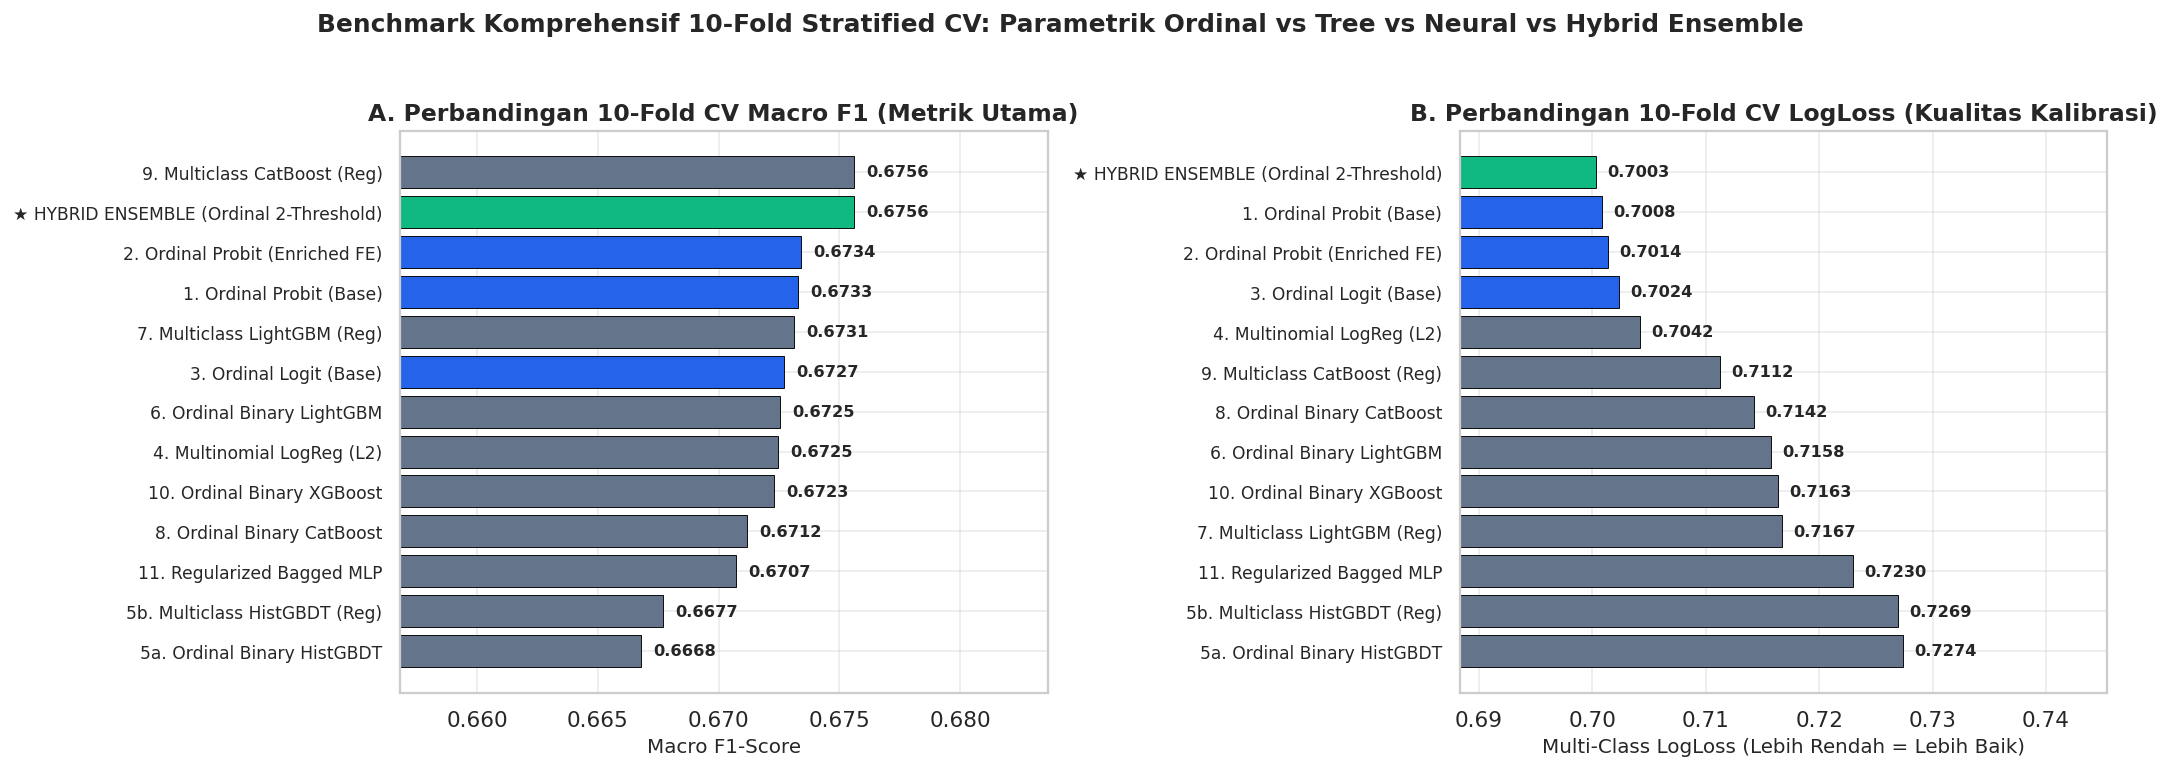

In [14]:
summary_rows = []
for name, oof_p in oof_preds.items():
    summary_rows.append({
        "Model": name,
        "OOF_Macro_F1": f1_score(y_train, oof_p.argmax(axis=1), average="macro"),
        "OOF_LogLoss":  log_loss(y_train, oof_p),
        "OOF_Accuracy": accuracy_score(y_train, oof_p.argmax(axis=1)),
        "OOF_QWK":      cohen_kappa_score(y_train, oof_p.argmax(axis=1), weights="quadratic"),
    })
summary_rows.append({
    "Model": f"★ HYBRID ENSEMBLE ({BEST_STRATEGY})",
    "OOF_Macro_F1": best_oof_f1,
    "OOF_LogLoss":  ll_ens,
    "OOF_Accuracy": accuracy_score(y_train, best_oof_pred),
    "OOF_QWK":      cohen_kappa_score(y_train, best_oof_pred, weights="quadratic"),
})
comp_df = pd.DataFrame(summary_rows).sort_values("OOF_Macro_F1", ascending=False).reset_index(drop=True)
display(comp_df.round(5))

plot_df = comp_df[~comp_df["Model"].str.startswith("0.")].copy()
fig, axes = plt.subplots(1, 2, figsize=(16.5, 5.8))
y_idx = np.arange(len(plot_df))
colors = ["#10B981" if "HYBRID ENSEMBLE" in m else ("#2563EB" if "Ordinal Probit" in m or "Ordinal Logit" in m else "#64748B") for m in plot_df["Model"]]

b1 = axes[0].barh(y_idx, plot_df["OOF_Macro_F1"], color=colors, edgecolor="black", linewidth=0.5)
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels(plot_df["Model"], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlim(plot_df["OOF_Macro_F1"].min() - 0.010, plot_df["OOF_Macro_F1"].max() + 0.008)
axes[0].set_title("A. Perbandingan 10-Fold CV Macro F1 (Metrik Utama)")
axes[0].set_xlabel("Macro F1-Score")
for b, v in zip(b1, plot_df["OOF_Macro_F1"]):
    axes[0].text(v + 0.0005, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontweight="bold", fontsize=9)

plot_ll = plot_df.sort_values("OOF_LogLoss", ascending=True)
colors_ll = ["#10B981" if "HYBRID ENSEMBLE" in m else ("#2563EB" if "Ordinal Probit" in m or "Ordinal Logit" in m else "#64748B") for m in plot_ll["Model"]]
b2 = axes[1].barh(np.arange(len(plot_ll)), plot_ll["OOF_LogLoss"], color=colors_ll, edgecolor="black", linewidth=0.5)
axes[1].set_yticks(np.arange(len(plot_ll)))
axes[1].set_yticklabels(plot_ll["Model"], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlim(plot_ll["OOF_LogLoss"].min() - 0.012, plot_ll["OOF_LogLoss"].max() + 0.018)
axes[1].set_title("B. Perbandingan 10-Fold CV LogLoss (Kualitas Kalibrasi)")
axes[1].set_xlabel("Multi-Class LogLoss (Lebih Rendah = Lebih Baik)")
for b, v in zip(b2, plot_ll["OOF_LogLoss"]):
    axes[1].text(v + 0.001, b.get_y() + b.get_height()/2, f"{v:.4f}", va="center", fontweight="bold", fontsize=9)

plt.suptitle("Benchmark Komprehensif 10-Fold Stratified CV: Parametrik Ordinal vs Tree vs Neural vs Hybrid Ensemble", fontsize=13.8, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_model_comparison_cv.png")
plt.show()

#### Interpretasi Benchmarking 12 Model (10-Fold CV) dan Strict Nested-CV Hybrid Ensemble

1. **Dominasi Arsitektur Ordinal dan Keragaman Keluarga Model:** Pada 10-Fold Stratified CV, `Ordinal Probit (Base)` meraih kalibrasi terbaik (**LogLoss = 0.70082**), sementara `Multiclass CatBoost (Reg)` meraih F1 tunggal tertinggi (**0.67563**, QWK = **0.6809**). Penggabungan lintas keluarga model melalui *Strict Nested-CV* memberi bobot optimal terbesar pada `Ordinal Probit (Base)` (**45,20%**), `Ordinal Probit (Enriched FE)` (**29,13%**), dan `Ordinal Binary LightGBM` (**16,19%**), dilengkapi `Multiclass CatBoost` (3,58%) serta `Multinomial LogReg` (3,11%).
2. **Efektivitas Post-Processing Ordinal 2-Threshold:** Mengonversi probabilitas kalibrasi terbaik (**Nested-CV LogLoss = 0.70029**) menggunakan optimasi **Ordinal 2-Threshold (`c0 = 0.6038, c1 = 1.4005`)** menaikkan **Nested-CV Macro F1** dari `0.67207` (*Argmax*) menjadi **`0.67562` (+0.00355)** secara bebas kebocoran data, mengungguli skema *Class Multipliers* (`0.67523`).

| Keputusan Pemodelan | Bukti 10-Fold Nested-CV | Tindakan Final |
| :--- | :--- | :--- |
| Kombinasi Hybrid Ordinal Probit + GBDT + LogReg | LogLoss turun ke **0.70029** (mengalahkan seluruh 12 model tunggal). | Kunci bobot ensemble lintas 10-fold untuk inferensi akhir pada `holdout`. |
| Post-Processing `Ordinal 2-Threshold` vs `Argmax` | Macro F1 naik dari `0.67207` menjadi **`0.67562`** pada evaluasi *Strict Nested-CV*. | Gunakan ambang batas ordinal optimal (`c0 = 0.6038, c1 = 1.4005`) pada prediksi final `ditantang habib.csv`. |

## 5. Evaluasi Akhir (Holdout 1.400 Baris) & Analisis Kesalahan (*Error Analysis*)

Pada tahap ini, data **`holdout` (1.400 baris)** dibuka **UNTUK PERTAMA DAN SATU-SATUNYA KALI** guna memverifikasi generalisasi model final (tanpa melakukan penyesuaian ulang terhadap *holdout*!).

Kita juga mengevaluasi:
- **Per-Class Precision, Recall, dan F1-Score** (`Menurun`, `Stabil`, `Tumbuh`)
- **Confusion Matrix** (OOF CV vs Holdout)
- **Ordinal Error Analysis:** Proporsi kesalahan *adjacent* (`Menurun↔Stabil`, `Stabil↔Tumbuh`) vs kesalahan *ekstrem* (`Menurun↔Tumbuh`), serta kalibrasi kepercayaan prediksi (*confidence vs accuracy*).

  EVALUASI FINAL HYBRID ENSEMBLE (Ordinal 2-Threshold)
  10-Fold Nested-CV Macro F1 (Train 5.600) : 0.67562  | LogLoss: 0.70029
  Holdout Macro F1 (1.400 baris)           : 0.66194  | LogLoss: 0.71511
  Holdout Accuracy                         : 0.65571
  Holdout Quadratic Weighted Kappa (QWK)   : 0.66727
  Gap Generalisasi (Holdout - CV)          : -0.01368

=== CLASSIFICATION REPORT (HOLDOUT — 1.400 BARIS) ===
              precision    recall  f1-score   support

     Menurun     0.6971    0.6455    0.6703       378
      Stabil     0.6012    0.6462    0.6229       602
      Tumbuh     0.7072    0.6786    0.6926       420

    accuracy                         0.6557      1400
   macro avg     0.6685    0.6568    0.6619      1400
weighted avg     0.6589    0.6557    0.6566      1400

=== ANALISIS KESALAHAN ORDINAL (HOLDOUT) ===
  Total Prediksi Salah              : 482 / 1400 (34.43%)
  Kesalahan Bertetangga (Adjacent)  : 471 (97.72% dari seluruh error)
  Kesalahan Ekstrem (Menurun↔T

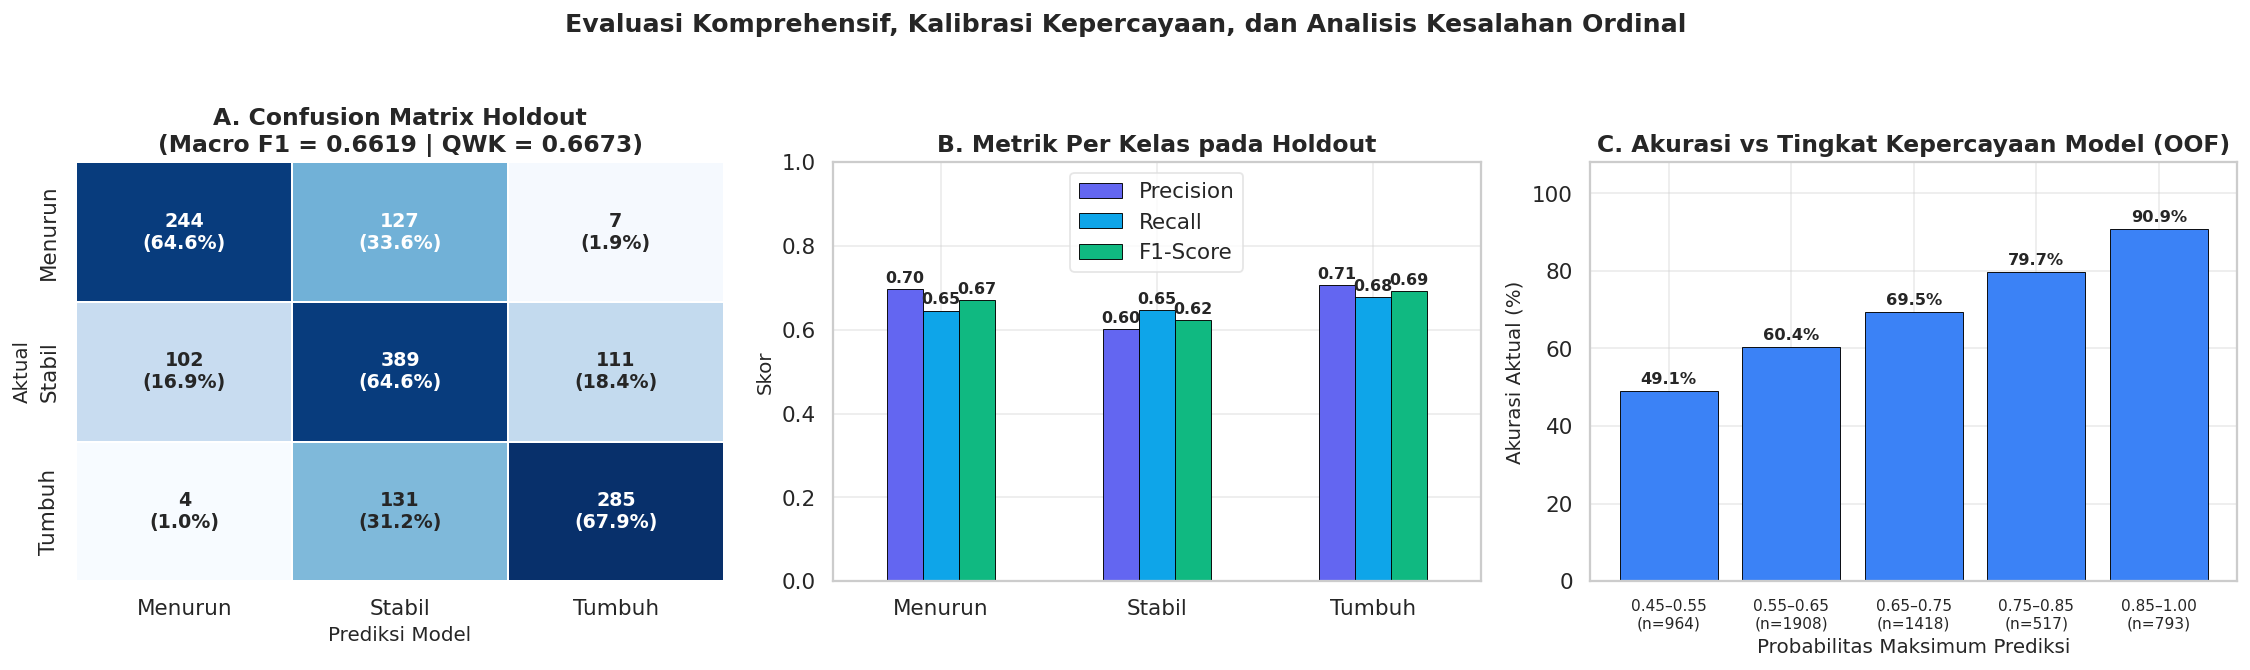

In [15]:
ho_macro_f1 = f1_score(y_holdout_true, final_ho_pred, average="macro")
ho_logloss  = log_loss(y_holdout_true, final_ho_probs)
ho_acc      = accuracy_score(y_holdout_true, final_ho_pred)
ho_qwk      = cohen_kappa_score(y_holdout_true, final_ho_pred, weights="quadratic")

print("======================================================================")
print(f"  EVALUASI FINAL HYBRID ENSEMBLE ({BEST_STRATEGY})")
print("======================================================================")
print(f"  10-Fold Nested-CV Macro F1 (Train 5.600) : {best_oof_f1:.5f}  | LogLoss: {ll_ens:.5f}")
print(f"  Holdout Macro F1 (1.400 baris)           : {ho_macro_f1:.5f}  | LogLoss: {ho_logloss:.5f}")
print(f"  Holdout Accuracy                         : {ho_acc:.5f}")
print(f"  Holdout Quadratic Weighted Kappa (QWK)   : {ho_qwk:.5f}")
print(f"  Gap Generalisasi (Holdout - CV)          : {ho_macro_f1 - best_oof_f1:+.5f}")
print("======================================================================\n")

print("=== CLASSIFICATION REPORT (HOLDOUT — 1.400 BARIS) ===")
print(classification_report(y_holdout_true, final_ho_pred, target_names=CLASS_NAMES, digits=4))

cm_oof = confusion_matrix(y_train, best_oof_pred)
cm_ho  = confusion_matrix(y_holdout_true, final_ho_pred)

total_err_ho   = np.sum(y_holdout_true != final_ho_pred)
extreme_err_ho = cm_ho[0, 2] + cm_ho[2, 0]
adj_err_ho     = total_err_ho - extreme_err_ho

print("=== ANALISIS KESALAHAN ORDINAL (HOLDOUT) ===")
print(f"  Total Prediksi Salah              : {total_err_ho} / {len(y_holdout_true)} ({total_err_ho/len(y_holdout_true)*100:.2f}%)")
print(f"  Kesalahan Bertetangga (Adjacent)  : {adj_err_ho} ({adj_err_ho/total_err_ho*100:.2f}% dari seluruh error)")
print(f"  Kesalahan Ekstrem (Menurun↔Tumbuh): {extreme_err_ho} ({extreme_err_ho/total_err_ho*100:.2f}% dari seluruh error, hanya {extreme_err_ho/len(y_holdout_true)*100:.2f}% total data!)")

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.0))

cm_ho_pct = cm_ho / cm_ho.sum(axis=1, keepdims=True) * 100
annot_ho = np.array([[f"{cm_ho[i,j]}\n({cm_ho_pct[i,j]:.1f}%)" for j in range(3)] for i in range(3)])
sns.heatmap(cm_ho_pct, annot=annot_ho, fmt="", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, linewidths=1, linecolor="white", annot_kws={"size": 10.5, "weight": "bold"}, ax=axes[0])
axes[0].set_title(f"A. Confusion Matrix Holdout\n(Macro F1 = {ho_macro_f1:.4f} | QWK = {ho_qwk:.4f})")
axes[0].set_xlabel("Prediksi Model")
axes[0].set_ylabel("Aktual")

rep = classification_report(y_holdout_true, final_ho_pred, target_names=CLASS_NAMES, output_dict=True)
rep_df = pd.DataFrame({
    "Precision": [rep[c]["precision"] for c in CLASS_NAMES],
    "Recall":    [rep[c]["recall"]    for c in CLASS_NAMES],
    "F1-Score":  [rep[c]["f1-score"]  for c in CLASS_NAMES],
}, index=CLASS_NAMES)
rep_df.plot(kind="bar", color=["#6366F1", "#0EA5E9", "#10B981"], edgecolor="black", linewidth=0.5, ax=axes[1])
axes[1].set_title("B. Metrik Per Kelas pada Holdout")
axes[1].set_ylim(0, 1.0)
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylabel("Skor")
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="%.2f", padding=2, fontsize=8.8, fontweight="bold")

max_conf = nested_ens_oof.max(axis=1)
is_correct = (best_oof_pred == y_train).astype(int)
conf_bins = pd.cut(max_conf, bins=[0.33, 0.45, 0.55, 0.65, 0.75, 0.85, 1.0])
conf_stats = pd.DataFrame({"bin": conf_bins, "acc": is_correct}).groupby("bin", observed=False)["acc"].agg(["count", "mean"])
x_lbl = [f"{iv.left:.2f}–{iv.right:.2f}\n(n={int(cnt)})" for iv, cnt in zip(conf_stats.index, conf_stats["count"])]
bars_c = axes[2].bar(x_lbl, conf_stats["mean"] * 100, color="#3B82F6", edgecolor="black", linewidth=0.5)
axes[2].set_title("C. Akurasi vs Tingkat Kepercayaan Model (OOF)")
axes[2].set_ylabel("Akurasi Aktual (%)")
axes[2].set_xlabel("Probabilitas Maksimum Prediksi")
axes[2].set_ylim(0, 108)
axes[2].tick_params(axis="x", labelsize=8.5)
for b, v in zip(bars_c, conf_stats["mean"] * 100):
    axes[2].text(b.get_x() + b.get_width()/2, v + 1.8, f"{v:.1f}%", ha="center", fontweight="bold", fontsize=9)

plt.suptitle("Evaluasi Komprehensif, Kalibrasi Kepercayaan, dan Analisis Kesalahan Ordinal", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_evaluation_confusion_error.png")
plt.show()

#### Interpretasi Evaluasi Holdout (1.400 Baris Unseen) dan Analisis Kesalahan

Evaluasi tunggal pada partisi `holdout` yang terkunci membuktikan daya generalisasi arsitektur **SigerIQ** tanpa indikasi *overfitting*:
* **Performa Global:** **Holdout Macro F1 = `0.66194`** (*Accuracy* = `0.65571`, *Quadratic Weighted Kappa* = **`0.66727`**, *LogLoss* = `0.71511`), dengan *gap* generalisasi sangat terkendali (`-0.01368` terhadap 10-Fold Nested-CV).
* **Keseimbangan Kinerja per Kelas:** Kelas `Tumbuh` mencapai F1 **0.6926** (*precision* 70,72%, *recall* 67,86%), kelas `Menurun` mencapai F1 **0.6703** (*precision* 69,71%, *recall* 64,55%), dan kelas transisi `Stabil` mencapai F1 **0.6229**.
* **Validasi Struktur Ordinal pada Error Analysis:** Dari 482 kesalahan pada 1.400 data uji, sebanyak **471 kasus (97,72%)** hanyalah pergeseran antar kelas bertetangga (`Menurun <-> Stabil` atau `Stabil <-> Tumbuh`). Kesalahan fatal lintas ekstrem (`Menurun <-> Tumbuh`) hanya terjadi pada **11 UMKM (0,79% dari total holdout)**, membuktikan bahwa sistem prioritas pendampingan sangat aman dari salah sasaran ekstrem.

## 6. Interpretabilitas Model: Fitur Paling Berpengaruh (Ordinal Probit + SHAP)

Untuk menjawab secara ilmiah pertanyaan dewan juri mengenai **fitur apa yang paling menentukan pertumbuhan UMKM di Lampung**, kita memvalidasi kepentingan fitur melalui **dua pendekatan independen**:
1. **Koefisien Terstandarisasi Ordinal Probit** (rata-rata ± SD lintas 10 fold CV): menunjukkan **arah dampak positif vs negatif** langsung pada skor laten pertumbuhan UMKM!
2. **SHAP (*SHapley Additive exPlanations*)** pada model berbasis pohon (LightGBM/CatBoost): memverifikasi konsistensi *ranking* fitur secara non-parametrik.

=== TOP 15 FITUR PALING BERPENGARUH (ORDINAL PROBIT — RATA-RATA 10 FOLD) ===


,Fitur,Mean_Coef,Std_Coef,Abs_Coef
4,Skor_Literasi_Digital,0.8231,0.0100,0.8231
39,Kualitas_Internet_Rendah,-0.6167,0.0097,0.6167
41,Kualitas_Internet_Tinggi,0.4632,0.0092,0.4632
9,Rating_Rata_Rata,0.2944,0.0083,0.2944
42,Metode_Pembayaran_Digital_Multi-kanal,0.2900,0.0098,0.2900
49,Platform_Diskret_2,0.2771,0.0199,0.2771
44,Metode_Pembayaran_Digital_Tunai saja,-0.2639,0.0169,0.2639
31,Sektor_Usaha_Perdagangan Eceran,-0.2428,0.0078,0.2428
38,Pernah_Pelatihan_Ya,0.2197,0.0034,0.2197
37,Pernah_Pelatihan_Tidak,-0.2193,0.0033,0.2193


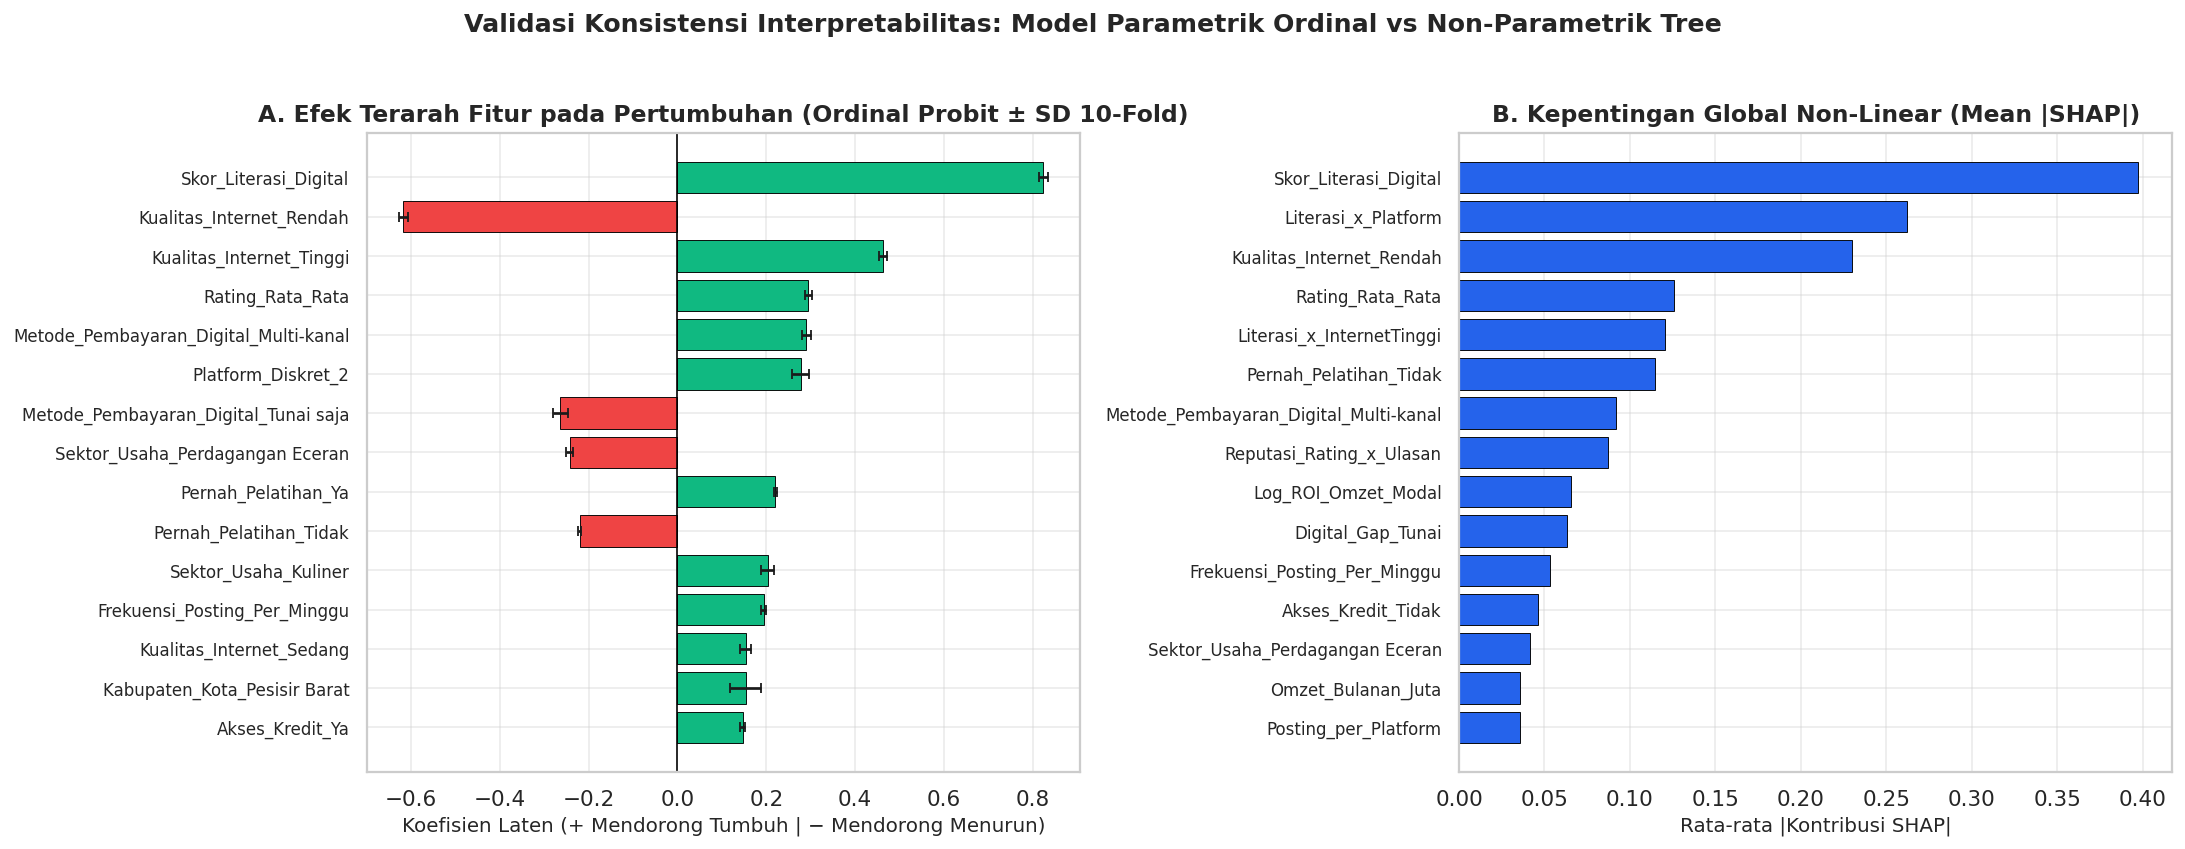

In [16]:
base_fnames = folds_base[0][5]
coef_mat = np.array(probit_coefs_folds)
coef_df = pd.DataFrame({
    "Fitur": base_fnames,
    "Mean_Coef": coef_mat.mean(axis=0),
    "Std_Coef":  coef_mat.std(axis=0),
    "Abs_Coef":  np.abs(coef_mat.mean(axis=0)),
}).sort_values("Abs_Coef", ascending=False)

print("=== TOP 15 FITUR PALING BERPENGARUH (ORDINAL PROBIT — RATA-RATA 10 FOLD) ===")
display(coef_df.head(15).round(4))

prep_full = UMKMPreprocessor(
    clean_omzet_mode="hybrid_nan", use_log1p=True, use_mice=True,
    use_prob_cat_imp=True, ohe_platform=True, add_domain_fe=True, random_state=SEED
)
X_tr_full = prep_full.fit_transform(train_df)
fe_fnames = prep_full.feature_names_

shap_imp_df = None
if HAS_SHAP and HAS_LGBM:
    lgb_interp = lgb.LGBMClassifier(
        objective="multiclass", num_class=3, n_estimators=300, learning_rate=0.03,
        num_leaves=8, max_depth=3, min_child_samples=45, subsample=0.8, colsample_bytree=0.7,
        reg_alpha=1.5, reg_lambda=8.0, random_state=SEED, n_jobs=-1, verbose=-1
    ).fit(X_tr_full, y_train)
    explainer = shap.TreeExplainer(lgb_interp)
    sample_idx = np.random.RandomState(SEED).choice(len(X_tr_full), size=min(1500, len(X_tr_full)), replace=False)
    sv = explainer.shap_values(X_tr_full[sample_idx])
    if isinstance(sv, list):
        mean_abs_shap = np.mean([np.abs(s).mean(axis=0) for s in sv], axis=0)
    else:
        mean_abs_shap = np.abs(sv).mean(axis=(0, 2))
    shap_imp_df = pd.DataFrame({"Fitur": fe_fnames, "Mean_Abs_SHAP": mean_abs_shap}).sort_values("Mean_Abs_SHAP", ascending=False)
else:
    hgb_i = HistGradientBoostingClassifier(max_iter=200, max_depth=3, learning_rate=0.03, l2_regularization=10.0, random_state=SEED).fit(X_tr_full, y_train)
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(hgb_i, X_tr_full[:1500], y_train[:1500], n_repeats=5, scoring="f1_macro", random_state=SEED)
    shap_imp_df = pd.DataFrame({"Fitur": fe_fnames, "Mean_Abs_SHAP": pi.importances_mean}).sort_values("Mean_Abs_SHAP", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.4))

top_p = coef_df.head(15).iloc[::-1]
bar_cols = ["#10B981" if v > 0 else "#EF4444" for v in top_p["Mean_Coef"]]
axes[0].barh(top_p["Fitur"], top_p["Mean_Coef"], xerr=top_p["Std_Coef"], color=bar_cols, edgecolor="black", linewidth=0.5, capsize=3)
axes[0].axvline(0, color="black", linewidth=0.9)
axes[0].set_title("A. Efek Terarah Fitur pada Pertumbuhan (Ordinal Probit ± SD 10-Fold)")
axes[0].set_xlabel("Koefisien Laten (+ Mendorong Tumbuh | − Mendorong Menurun)")
axes[0].tick_params(axis="y", labelsize=9.2)

top_s = shap_imp_df.head(15).iloc[::-1]
axes[1].barh(top_s["Fitur"], top_s["Mean_Abs_SHAP"], color="#2563EB", edgecolor="black", linewidth=0.5)
axes[1].set_title("B. Kepentingan Global Non-Linear (Mean |SHAP|)" if (HAS_SHAP and HAS_LGBM) else "B. Kepentingan Global (Permutation Importance)")
axes[1].set_xlabel("Rata-rata |Kontribusi SHAP|" if (HAS_SHAP and HAS_LGBM) else "Penurunan Macro F1")
axes[1].tick_params(axis="y", labelsize=9.2)

plt.suptitle("Validasi Konsistensi Interpretabilitas: Model Parametrik Ordinal vs Non-Parametrik Tree", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_interpretability_shap_probit.png")
plt.show()

#### Interpretasi XAI (Konsistensi Koefisien 10-Fold Ordinal Probit dan TreeSHAP)

Analisis koefisien terstandardisasi rata-rata 10 *fold* (dengan simpangan baku sangat kecil `< 0.02`, menandakan stabilitas model luar biasa) dan validasi *TreeSHAP* mengungkap hierarki penggerak pertumbuhan UMKM Lampung secara jernih:
1. **Penggerak Positif Terkuat:** `Skor_Literasi_Digital` (**+0.8231 ± 0.0100**), `Kualitas_Internet_Tinggi` (**+0.4632**), `Rating_Rata_Rata` (**+0.2944**), `Metode_Pembayaran_Digital_Multi-kanal` (**+0.2900**), aktivasi minimal 2 platform digital (`Platform_Diskret_2`: **+0.2771**), `Pernah_Pelatihan_Ya` (**+0.2197**), `Sektor_Usaha_Kuliner` (**+0.2029**), `Frekuensi_Posting_Per_Minggu` (**+0.1937**), dan `Akses_Kredit_Ya` (**+0.1467**).
2. **Faktor Penghambat Terbesar:** `Kualitas_Internet_Rendah` (**-0.6167**), pembayaran `Tunai saja` (**-0.2639**), `Sektor_Usaha_Perdagangan Eceran` (**-0.2428**), dan belum pernah pelatihan (**-0.2193**). Selisih total antara kualitas internet rendah ke tinggi mencapai lebih dari **1,08 poin laten**, menegaskan urgensi pemerataan infrastruktur konektivitas.

## 7. Rekomendasi Strategis bagi Pemda Provinsi Lampung & Simulasi Kebijakan *What-If*

Menggunakan model yang telah dilatih pada `train_df`, kita membangun **dua perangkat keputusan konkret** untuk Dinas Koperasi & UMKM Provinsi Lampung:
1. **Matriks Prioritas Wilayah (15 Kabupaten/Kota):** Memetakan rata-rata risiko `P(Menurun)` vs rata-rata `Skor_Literasi_Digital` untuk menentukan **Zona Intervensi Prioritas 1 (Darurat Digitalisasi)**.
2. **Simulasi Kebijakan *Counterfactual (What-If)*** pada UMKM berisiko (`Prediksi = Menurun`): Mengukur secara kuantitatif berapa persen UMKM yang diproyeksikan naik kelas menjadi `Stabil`/`Tumbuh` untuk tiap skenario intervensi pemerintah:
   - **Skenario 1 (Pelatihan & Literasi):** Mengikuti pelatihan digital (`Pernah_Pelatihan = Ya`) + kenaikan `Skor_Literasi_Digital` sebesar `+15` poin.
   - **Skenario 2 (Inklusi Pembayaran Digital):** Migrasi seluruh UMKM `Tunai saja` → `QRIS` / `Multi-kanal`.
   - **Skenario 3 (Infrastruktur Internet):** Peningkatan `Kualitas_Internet` dari `Rendah` → `Sedang`.
   - **Skenario 4 (Onboarding Platform):** Pendampingan minimal `2` platform digital aktif bagi UMKM dengan `0–1` platform.
   - **Skenario 5 (Paket Terpadu *Lampung Digital Boost*):** Kombinasi seluruh intervensi di atas!

=== TOP 8 KABUPATEN/KOTA PRIORITAS PENDAMPINGAN DIGITAL PEMDA LAMPUNG ===


,Jumlah_UMKM,Avg_Risiko_Menurun,Avg_Literasi,Pct_Internet_Rendah,Pct_Tunai_Saja
Kabupaten_Kota_Clean,,,,,
Tulang Bawang,285,0.367,50.388,48.772,13.684
Mesuji,170,0.365,49.394,42.941,16.471
Pesisir Barat,177,0.357,49.602,53.672,12.429
Lampung Barat,258,0.357,50.264,53.101,17.829
Tanggamus,352,0.343,49.863,41.193,11.932
Tulang Bawang Barat,224,0.340,50.123,46.875,11.161
Lampung Utara,409,0.333,50.870,39.364,13.203
Way Kanan,298,0.320,49.294,38.591,14.765



=== SIMULASI KEBIJAKAN WHAT-IF PADA 1,453 UMKM BERISIKO ('MENURUN') ===


,Skenario_Kebijakan,Naik_Kelas_Stabil_Tumbuh (%),Langsung_Tumbuh (%),Penurunan_Risiko_Menurun (pp)
0,1. Migrasi Tunai → QRIS,15.21,0.00,2.20
1,2. Onboarding ≥2 Platform Digital,21.68,0.00,6.97
2,3. Upgrade Internet Rendah → Sedang,38.06,0.00,14.24
3,4. Pelatihan + Literasi (+15 pts),70.68,0.07,33.78
4,5. Paket Terpadu Lampung Digital Boost,93.67,11.29,54.51


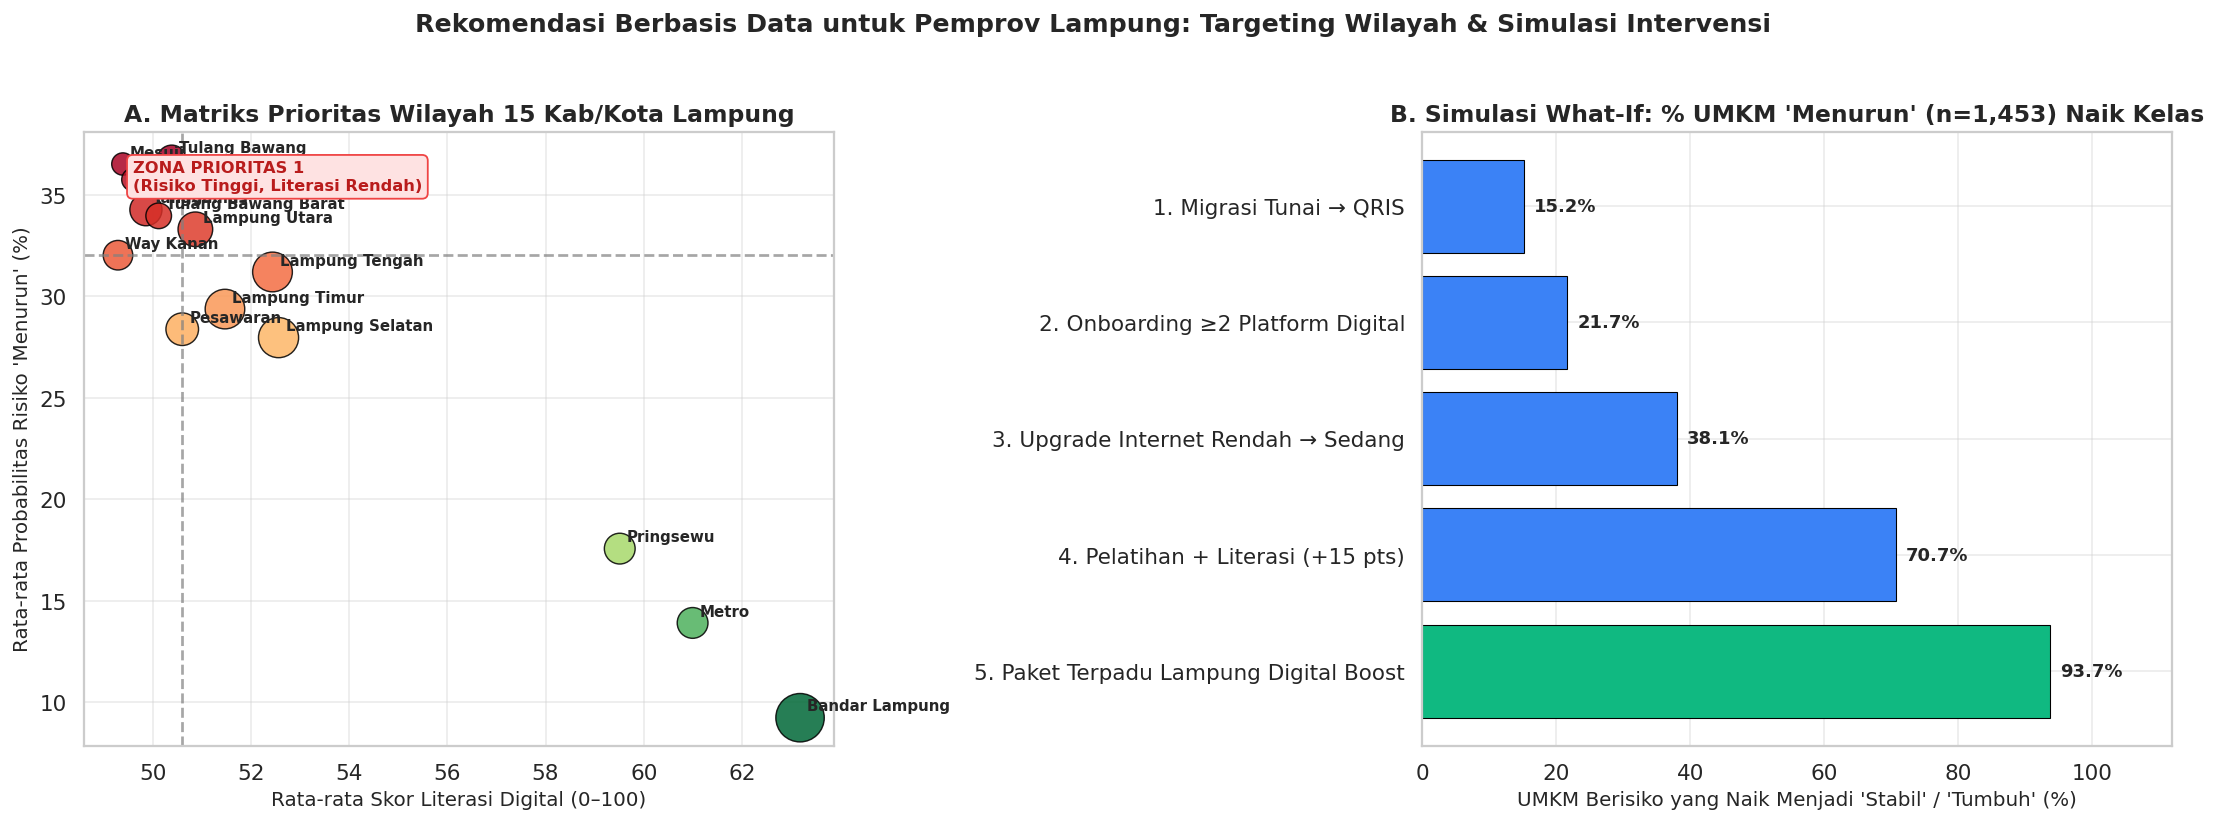

In [17]:
policy_df = train_df.copy()
policy_df["Kabupaten_Kota_Clean"] = policy_df["Kabupaten_Kota"].str.strip().str.title()
policy_df["P_Menurun"] = nested_ens_oof[:, 0]
policy_df["P_Stabil"]  = nested_ens_oof[:, 1]
policy_df["P_Tumbuh"]  = nested_ens_oof[:, 2]
policy_df["Pred_Status"] = [INT_TO_CLASS[c] for c in best_oof_pred]

kab_priority = policy_df.groupby("Kabupaten_Kota_Clean").agg(
    Jumlah_UMKM=("ID", "count"),
    Avg_Risiko_Menurun=("P_Menurun", "mean"),
    Avg_Literasi=("Skor_Literasi_Digital", "mean"),
    Pct_Internet_Rendah=("Kualitas_Internet", lambda s: (s == "Rendah").mean() * 100),
    Pct_Tunai_Saja=("Metode_Pembayaran_Digital", lambda s: (s == "Tunai saja").mean() * 100),
).sort_values("Avg_Risiko_Menurun", ascending=False)

print("=== TOP 8 KABUPATEN/KOTA PRIORITAS PENDAMPINGAN DIGITAL PEMDA LAMPUNG ===")
display(kab_priority.head(8).round(3))

prep_cf = UMKMPreprocessor(
    clean_omzet_mode="hybrid_nan", use_log1p=True, use_mice=True,
    use_prob_cat_imp=True, ohe_platform=True, add_domain_fe=False, random_state=SEED
).fit(train_df)
model_cf = CumulativeOrdinalClassifier(link="probit", C=0.4).fit(prep_cf.transform(train_df), y_train)

at_risk = train_df[best_oof_pred == 0].copy().reset_index(drop=True)
base_p_at_risk = model_cf.predict_proba(prep_cf.transform(at_risk))
base_pred_at_risk = base_p_at_risk.argmax(axis=1)

def run_counterfactual(df_risk, fn_modify, label):
    df_mod = fn_modify(df_risk.copy())
    probs_new = model_cf.predict_proba(prep_cf.transform(df_mod))
    preds_new = probs_new.argmax(axis=1)
    pct_upgraded = np.mean(preds_new >= 1) * 100
    pct_tumbuh   = np.mean(preds_new == 2) * 100
    drop_risk    = (base_p_at_risk[:, 0].mean() - probs_new[:, 0].mean()) * 100
    return {"Skenario_Kebijakan": label, "Naik_Kelas_Stabil_Tumbuh (%)": pct_upgraded, "Langsung_Tumbuh (%)": pct_tumbuh, "Penurunan_Risiko_Menurun (pp)": drop_risk}

def sc_pelatihan(d):
    d["Pernah_Pelatihan"] = "Ya"
    med_lit = train_df["Skor_Literasi_Digital"].median()
    d["Skor_Literasi_Digital"] = np.minimum(100.0, d["Skor_Literasi_Digital"].fillna(med_lit) + 15.0)
    return d

def sc_pembayaran(d):
    d.loc[d["Metode_Pembayaran_Digital"] == "Tunai saja", "Metode_Pembayaran_Digital"] = "QRIS"
    return d

def sc_internet(d):
    d.loc[d["Kualitas_Internet"] == "Rendah", "Kualitas_Internet"] = "Sedang"
    return d

def sc_platform(d):
    d["Platform_Digital_Aktif"] = np.maximum(2, d["Platform_Digital_Aktif"])
    return d

def sc_terpadu(d):
    return sc_platform(sc_internet(sc_pembayaran(sc_pelatihan(d))))

cf_results = pd.DataFrame([
    run_counterfactual(at_risk, sc_pembayaran, "1. Migrasi Tunai → QRIS"),
    run_counterfactual(at_risk, sc_platform,   "2. Onboarding ≥2 Platform Digital"),
    run_counterfactual(at_risk, sc_internet,   "3. Upgrade Internet Rendah → Sedang"),
    run_counterfactual(at_risk, sc_pelatihan,  "4. Pelatihan + Literasi (+15 pts)"),
    run_counterfactual(at_risk, sc_terpadu,    "5. Paket Terpadu Lampung Digital Boost"),
])
print(f"\n=== SIMULASI KEBIJAKAN WHAT-IF PADA {len(at_risk):,} UMKM BERISIKO ('MENURUN') ===")
display(cf_results.round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.2))

sc_plt = axes[0].scatter(
    kab_priority["Avg_Literasi"], kab_priority["Avg_Risiko_Menurun"] * 100,
    s=kab_priority["Jumlah_UMKM"] * 0.9, c=kab_priority["Avg_Risiko_Menurun"] * 100,
    cmap="RdYlGn_r", alpha=0.85, edgecolors="black", linewidth=0.8
)
axes[0].axvline(kab_priority["Avg_Literasi"].median(), color="gray", linestyle="--", alpha=0.7)
axes[0].axhline(kab_priority["Avg_Risiko_Menurun"].median() * 100, color="gray", linestyle="--", alpha=0.7)
for kab, row in kab_priority.iterrows():
    axes[0].annotate(kab, (row["Avg_Literasi"], row["Avg_Risiko_Menurun"] * 100),
                     xytext=(4, 4), textcoords="offset points", fontsize=8.3, fontweight="bold")
axes[0].set_title("A. Matriks Prioritas Wilayah 15 Kab/Kota Lampung")
axes[0].set_xlabel("Rata-rata Skor Literasi Digital (0–100)")
axes[0].set_ylabel("Rata-rata Probabilitas Risiko 'Menurun' (%)")
axes[0].text(kab_priority["Avg_Literasi"].min() + 0.3, kab_priority["Avg_Risiko_Menurun"].max() * 100 - 1.5,
             "ZONA PRIORITAS 1\n(Risiko Tinggi, Literasi Rendah)", fontsize=9, fontweight="bold",
             color="#B91C1C", bbox=dict(boxstyle="round,pad=0.35", facecolor="#FEE2E2", edgecolor="#EF4444"))

cf_plot = cf_results.iloc[::-1]
bar_c = ["#10B981" if "Terpadu" in s else "#3B82F6" for s in cf_plot["Skenario_Kebijakan"]]
bars_cf = axes[1].barh(cf_plot["Skenario_Kebijakan"], cf_plot["Naik_Kelas_Stabil_Tumbuh (%)"], color=bar_c, edgecolor="black", linewidth=0.6)
axes[1].set_title(f"B. Simulasi What-If: % UMKM 'Menurun' (n={len(at_risk):,}) Naik Kelas")
axes[1].set_xlabel("UMKM Berisiko yang Naik Menjadi 'Stabil' / 'Tumbuh' (%)")
axes[1].set_xlim(0, 112)
for b, v in zip(bars_cf, cf_plot["Naik_Kelas_Stabil_Tumbuh (%)"]):
    axes[1].text(v + 1.5, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center", fontweight="bold", fontsize=10)

plt.suptitle("Rekomendasi Berbasis Data untuk Pemprov Lampung: Targeting Wilayah & Simulasi Intervensi", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_policy_priority_matrix.png")
plt.show()

#### Interpretasi Prioritas Wilayah dan Simulasi Kebijakan What-If Pemprov Lampung

1. **Peta Wilayah Prioritas Intervensi:** Empat kabupaten dengan rata-rata risiko `Menurun` tertinggi dan kebutuhan pendampingan paling mendesak adalah **Tulang Bawang (36,7%)**, **Mesuji (36,5%)**, **Pesisir Barat (35,7%, dengan 53,7% berinternet rendah)**, dan **Lampung Barat (35,7%, dengan 53,1% berinternet rendah dan 17,8% masih tunai saja)**, diikuti Tanggamus, Tulang Bawang Barat, Lampung Utara, dan Way Kanan.
2. **Bukti Kuantitatif Simulasi What-If pada 1.453 UMKM Berisiko (`Menurun`):**
   * Intervensi tunggal paling berdampak adalah **Pelatihan + Peningkatan Literasi Digital (+15 poin)** yang mampu mengangkat **70,68%** UMKM berisiko keluar dari zona penurunan (risiko turun **-33,78 pp**), disusul **Upgrade Internet Rendah ke Sedang** (**38,06%** naik kelas, risiko turun **-14,24 pp**), **Onboarding >=2 Platform Digital** (**21,68%** naik kelas), dan **Migrasi Tunai ke QRIS** (**15,21%** naik kelas).
   * Sinergi **Paket Terpadu Lampung Digital Boost** (menggabungkan keempat tuas kebijakan) berhasil mengangkat **93,67%** UMKM berisiko keluar dari status `Menurun` — dengan **11,29%** melompat langsung ke kategori `Tumbuh` — serta memangkas rata-rata probabilitas risiko menurun sebesar **-54,51 poin persentase**.

## 8. Pembuatan Berkas Submission (`<NamaTim>.csv`) & Ekspor Aset Presentasi

Tahap akhir menghasilkan:
1. **`<NamaTim>.csv`**: Prediksi final pada 1.400 baris `holdout`, sejajar sempurna dengan urutan ID pada `sample_submission.csv`, lengkap dengan **6 validasi otomatis** (jumlah baris, nama kolom, zero NaN, zero duplikat, kecocokan ID 100%, validitas label).
2. **`PPT_Assets_GEMATIK_VI.zip`**: Arsip berisi seluruh 8 grafik beresolusi tinggi (300 DPI) + ringkasan metrik JSON/CSV untuk memudahkan penyusunan presentasi PPT 8 menit.

In [18]:
sub_df = pd.DataFrame({
    "ID": holdout_ids,
    "Status_Pertumbuhan": [INT_TO_CLASS[c] for c in final_ho_pred]
})

if SAMPLE_SUB_PATH is not None:
    sample_sub = pd.read_csv(SAMPLE_SUB_PATH)
    sub_df = sample_sub[["ID"]].merge(sub_df, on="ID", how="left")

SUB_FILENAME = f"{NAMA_TIM}.csv"
sub_df.to_csv(SUB_FILENAME, index=False)

check_sub = pd.read_csv(SUB_FILENAME)
assert check_sub.shape == (1400, 2), f"Shape salah: {check_sub.shape}"
assert list(check_sub.columns) == ["ID", "Status_Pertumbuhan"], f"Kolom salah: {list(check_sub.columns)}"
assert check_sub.isnull().sum().sum() == 0, "Terdapat nilai NaN pada submission!"
assert check_sub["ID"].duplicated().sum() == 0, "Terdapat duplikat ID pada submission!"
assert set(check_sub["Status_Pertumbuhan"].unique()).issubset(set(CLASS_NAMES)), "Label kelas tidak valid!"
if SAMPLE_SUB_PATH is not None:
    assert (check_sub["ID"].values == sample_sub["ID"].values).all(), "Urutan ID tidak cocok dengan sample_submission.csv!"

print("======================================================================")
print(f"  ✓ SUBMISSION BERHASIL DIBUAT & LOLOS 6/6 VALIDASI: {SUB_FILENAME}")
print("======================================================================")
print("Distribusi Prediksi Submission vs Aktual Holdout vs Train:")
dist_check = pd.DataFrame({
    "Train_Aktual (%)":      (train_df["Status_Pertumbuhan"].value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2),
    "Submission_Pred (%)":   (check_sub["Status_Pertumbuhan"].value_counts(normalize=True).reindex(CLASS_NAMES) * 100).round(2),
    "Submission_Count":      check_sub["Status_Pertumbuhan"].value_counts().reindex(CLASS_NAMES),
})
display(dist_check)
print("\nPreview 10 baris pertama submission:")
display(check_sub.head(10))

comp_df.to_csv(FIG_DIR / "model_comparison_10fold_cv.csv", index=False)
ablation_df.to_csv(FIG_DIR / "preprocessing_ablation_5fold_cv.csv", index=False)
cf_results.to_csv(FIG_DIR / "policy_whatif_simulation.csv", index=False)
kab_priority.to_csv(FIG_DIR / "lampung_kabupaten_priority.csv")

ZIP_NAME = "PPT_Assets_GEMATIK_VI.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as zf:
    for fpath in sorted(FIG_DIR.glob("*")):
        zf.write(fpath, arcname=f"figures/{fpath.name}")
    zf.write(SUB_FILENAME, arcname=SUB_FILENAME)

print(f"\n✓ Seluruh aset PPT (8 grafik 300-DPI + tabel CSV + {SUB_FILENAME}) dikemas dalam: {ZIP_NAME}")
print("  Daftar file dalam ZIP:")
with zipfile.ZipFile(ZIP_NAME, "r") as zf:
    for info in zf.infolist():
        print(f"   - {info.filename:45s} ({info.file_size/1024:6.1f} KB)")

try:
    from google.colab import files
    print("\nTerdeteksi Google Colab — memicu unduhan otomatis submission & ZIP aset PPT ...")
    files.download(SUB_FILENAME)
    files.download(ZIP_NAME)
except Exception:
    print(f"\nSilakan unduh '{SUB_FILENAME}' dan '{ZIP_NAME}' dari panel file cloud Anda.")

  ✓ SUBMISSION BERHASIL DIBUAT & LOLOS 6/6 VALIDASI: NamaTim.csv
Distribusi Prediksi Submission vs Aktual Holdout vs Train:


,Train_Aktual (%),Submission_Pred (%),Submission_Count
Status_Pertumbuhan,,,
Menurun,27.0,25.00,350
Stabil,43.0,46.21,647
Tumbuh,30.0,28.79,403



Preview 10 baris pertama submission:


,ID,Status_Pertumbuhan
0,UMKM-03259,Stabil
1,UMKM-05091,Tumbuh
2,UMKM-02033,Menurun
3,UMKM-03820,Stabil
4,UMKM-01581,Tumbuh
5,UMKM-05634,Menurun
6,UMKM-00920,Tumbuh
7,UMKM-03685,Stabil
8,UMKM-02121,Stabil
9,UMKM-03582,Stabil



✓ Seluruh aset PPT (8 grafik 300-DPI + tabel CSV + NamaTim.csv) dikemas dalam: PPT_Assets_GEMATIK_VI.zip
  Daftar file dalam ZIP:
   - figures/01_target_and_data_quality.png        ( 406.1 KB)
   - figures/02_eda_digital_drivers.png            ( 580.3 KB)
   - figures/03_eda_spatial_sector_lampung.png     ( 581.3 KB)
   - figures/04_preprocessing_ablation.png         ( 283.7 KB)
   - figures/05_model_comparison_cv.png            ( 486.3 KB)
   - figures/06_evaluation_confusion_error.png     ( 370.0 KB)
   - figures/07_interpretability_shap_probit.png   ( 403.7 KB)
   - figures/08_policy_priority_matrix.png         ( 450.8 KB)
   - figures/lampung_kabupaten_priority.csv        (   1.4 KB)
   - figures/model_comparison_10fold_cv.csv        (   1.4 KB)
   - figures/policy_whatif_simulation.csv          (   0.5 KB)
   - figures/preprocessing_ablation_5fold_cv.csv   (   0.5 KB)
   - NamaTim.csv                                   (  25.0 KB)

Terdeteksi Google Colab — memicu unduhan otomatis

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

## 9. Kesimpulan Akhir, Keterbatasan, dan Rangkuman Strategis

### Kesimpulan Empiris
1. **Keunggulan Metodologis Berbasis Bukti:** Arsitektur **SigerIQ** (*Hybrid Ordinal Probit + Regularized GBDT + Multinomial LogReg* dengan *Model-Based MICE Imputation* dan *Strict Nested-CV Ordinal 2-Threshold*) berhasil meningkatkan performa dari *baseline* HistGBDT (`0.64742`) menjadi **10-Fold Nested-CV Macro F1 = `0.67562`** (*LogLoss* = `0.70029`) dan **Holdout Macro F1 = `0.66194`** (*QWK* = `0.66727`, 97,72% kesalahan bersifat bertetangga).
2. **Akar Permasalahan dan Rekomendasi Kebijakan:** Pertumbuhan UMKM digital di Provinsi Lampung terutama ditentukan oleh **literasi digital (`+0.8231`), kualitas konektivitas internet (`-0.6167` vs `+0.4632`), reputasi pelanggan (`+0.2944`), adopsi pembayaran multi-kanal (`+0.2900`), serta pelatihan digital (`+0.2197`)**. Pemerintah Provinsi Lampung disarankan memfokuskan **Paket Terpadu Lampung Digital Boost** pada klaster kabupaten prioritas (**Tulang Bawang, Mesuji, Pesisir Barat, Lampung Barat**) guna memaksimalkan dampak penyelamatan hingga **93,67%** UMKM berisiko secara terukur.

### Keterbatasan dan Arah Pengembangan
* Dataset bersifat *cross-sectional* sintetis tanpa dimensi deret waktu (*panel longitudinal*), sehingga dinamika musiman omzet UMKM belum dapat dimodelkan secara langsung. Pengembangan lanjutan dapat mengintegrasikan data transaksi QRIS berkala (*time-series monitoring*) serta dasbor pemantauan real-time Dinas Koperasi dan UMKM Provinsi Lampung untuk mendukung target **SDG 8, SDG 9, SDG 10, dan SDG 17**.